# Шапка
ML-HW11-v1 TEAM-11. LongRAG и LightRAG по резюме
- Руденко Евгений Александрович
- Сажин Семён Михайлович
- Тихомиров Алексей Константинович

## Подготовка и материалы

Домашняя работа: продолжение проекта из ML-HW10

**Цель:** доработать свою RAG-систему, применить LongRAG и LightRAG и проверить, как способы поиска и гиперпараметры влияют на качество ответов.

1. Подготовьте проект и изучите материалы

Возьмите **свой проект и данные из ML-HW10**. Сохраните прежнюю RAG как базовый вариант для сравнения. Если проект основан на резюме, используйте тот же обезличенный корпус. Новый проект создавать не нужно.

Изучите презентацию и оба ноутбука. В **RAG with OpenAI.ipynb** разберите подготовку текста, embeddings, поиск FAISS и генерацию; в **Multimodal RAG.ipynb** — транскрипцию, кадры, CLIP и поиск текста и изображений. Кратко запишите: библиотека → назначение → что используете в своём проекте.

Запустите применимые части кода на небольшом примере своих данных. Настройте пути и зависимости; проверьте передачу текущего вопроса и контекста в генерацию. Для текстового проекта обработка видео и изображений **не обязательна**, но разбор обоих ноутбуков обязателен.

Дополните прежние проверочные вопросы до **12**: по 3 на прямой факт, объединение нескольких источников, обобщение и отсутствие ответа в базе. Заранее укажите ожидаемые факты и источники. При необходимости добавьте связанные документы одинаково во все варианты RAG.

**Важно:** приложенные ноутбуки не содержат готовых реализаций LongRAG и LightRAG. Это примеры подготовки данных, поиска и генерации; два новых подхода нужно добавить отдельно.

### Данные и запуск

В корпусе 400 обезличенных резюме. Номер в ID показывает место резюме в корпусе, поэтому первые 18 исходных резюме обозначены R1–R18. Одинаковые ID используются в ответах и ссылках на найденные фрагменты.

Для запуска нужна полная копия репозитория, Python с Jupyter и работающий Ollama с моделью qwen3:4b-instruct. Установите пакеты faiss-cpu, filelock, httpx, lightrag-hku==1.5.7, matplotlib, networkx, numpy, pandas, torch и transformers в окружение ядра. Для первого запуска нужны текстовые модели MiniLM и токенизатор Qwen, загружаемые с Hugging Face. Откройте ноутбук из копии репозитория. Для другого рабочего каталога задайте HW11_REPO_DIR. Переменная OLLAMA_BASE_URL задаёт адрес сервера. По умолчанию используется локальный Ollama на порту 11434. В data/ML-HW11/ доступны корпус, отдельные тексты резюме и переносимый индекс. Из сохранённых векторов быстро собираются индексы FAISS. Готовый граф LightRAG загружается, когда совпадают корпус, модель и размер окна Ollama. При отсутствии совместимого файла соответствующий индекс строится заново.

В примере RAG with OpenAI NumPy хранит эмбеддинги, FAISS ищет близкие тексты, а модель отвечает по переданным фрагментам. Здесь сохраняется этот порядок, с MiniLM для эмбеддингов и Ollama для генерации. В примере Multimodal RAG FFmpeg и MoviePy извлекают звук и кадры, модель транскрибирует звук, а CLIP сопоставляет изображения и текст. Резюме уже представлены текстом, поэтому в работе используется поиск по фрагментам документов.

Поиск, работа с индексами и вопросы подключаются из Python-модулей лабораторной. Тем же интерфейсом может пользоваться чат.

In [1]:
import json
import logging
import os
import sys
from dataclasses import asdict
from html import escape
from importlib.metadata import version
from pathlib import Path
from textwrap import fill

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
from filelock import FileLock
from IPython.display import HTML, Markdown, display
from lightrag.utils import setup_logger

start = Path(os.getenv("HW11_REPO_DIR", str(Path.cwd()))).resolve()
ROOT = next((directory for directory in (start, *start.parents)
             if (directory / "data" / "resumes_ru_6000_labeled.csv").is_file()
             and (directory / "labs" / "ML-HW10" / "rag_system.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Откройте ноутбук из копии репозитория или укажите её путь в HW11_REPO_DIR.")

sys.path.insert(0, str(ROOT))
from labs.ml_hw11.core import (
    EMBEDDINGS, INSTRUCTION, MODEL, Ollama, ResumeIndex, Study, fingerprint, load_corpus, runtime_dir,
)
from labs.ml_hw11.experiment import (
    BASELINE, INITIAL, LIGHT, UPDATE_AFTER, UPDATE_BEFORE, UPDATE_NEW, UPDATE_OLD, UPDATE_OTHER,
    VARIANTS, Experiment, context_distances, export_config, measure_local_indices,
    read_json, save_json,
)
from labs.ml_hw11.light import LightIndex
from labs.ml_hw11.questions import questions_for

### Состав корпуса и вопросы

In [2]:
def show_table(frame, description, widths=None, *, min_width=0):
    print(description)
    layout = ("border-bottom:1px solid #a4a4a4;padding:6px 8px;text-align:left;"
              "vertical-align:top;white-space:normal;overflow-wrap:anywhere;max-width:none")
    columns = [f'<col style="width:{width}%">' for width in widths] if widths else []
    headings = "".join(f'<th scope="col" style="{layout}">{escape(str(name))}</th>'
                       for name in frame.columns)
    rows = []
    for row in frame.itertuples(index=False, name=None):
        cells = []
        for value in row:
            content = "—" if pd.isna(value) else escape(str(value)).replace("\n", "<br>")
            cells.append(f'<td style="{layout}">{content}</td>')
        rows.append("<tr>" + "".join(cells) + "</tr>")
    display(HTML(
        '<div style="overflow-x:auto">'
        f'<table style="width:100%;min-width:{min_width}px;table-layout:fixed;border-collapse:collapse;">'
        + '<colgroup>' + "".join(columns) + '</colgroup>'
        + '<thead><tr>' + headings + '</tr></thead><tbody>' + "".join(rows) + '</tbody></table></div>'
    ))


OLLAMA_BASE_URL = os.getenv("OLLAMA_BASE_URL") or "http://127.0.0.1:11434"
# Общая системная инструкция для финальных ответов трёх методов.
SYSTEM_PROMPT = INSTRUCTION
CORPUS_SIZE = 400
runtime = runtime_dir()
setup_logger("lightrag", "ERROR", log_file_path=str(runtime / "lightrag.log"))
logging.getLogger("nano-vectordb").setLevel(logging.WARNING)

corpus = load_corpus(CORPUS_SIZE)
questions = questions_for(CORPUS_SIZE)
index = ResumeIndex(corpus, runtime)
composition = pd.Series([resume.category for resume in corpus]).value_counts().rename("Число резюме")
show_table(composition.rename_axis("Категория").reset_index(),
           "Как распределены 400 резюме по профессиональным категориям.", (76, 24))
show_table(pd.DataFrame([
    {"ID": q.id, "Вопрос": q.text, "Ожидаемый ответ": q.expected,
     "Источники эталона": ", ".join(q.sources) or "—"}
    for q in questions
]), "12 согласованных вопросов, эталоны ответов и подтверждающие резюме.", (8, 43, 35, 14))
packages = ("faiss-cpu", "filelock", "httpx", "lightrag-hku", "matplotlib", "networkx",
            "numpy", "pandas", "torch", "transformers")
print(f"Модель: {MODEL}. Текстовые эмбеддинги: {EMBEDDINGS}.")
print(f"Системный промпт финального ответа\n{SYSTEM_PROMPT}")
versions = pd.Series({name: version(name) for name in packages}, name="Версия")
show_table(versions.rename_axis("Пакет").reset_index(), "Версии библиотек в окружении эксперимента.")

Как распределены 400 резюме по профессиональным категориям.


Категория,Число резюме
Медицина и здравоохранение,74
Строительство и ремонт,73
Торговля и продажи,70
Транспорт и логистика,69
Образование и наука,65
Финансы и бухгалтерия,49


12 согласованных вопросов, эталоны ответов и подтверждающие резюме.


ID,Вопрос,Ожидаемый ответ,Источники эталона
F1,Кто из кандидатов умеет делать химическую завивку и окраску волос?,Резюме R1 подтверждает химическую завивку и окраску волос.,R1
F2,"У какого кандидата есть опыт полевых визитов к педиатрам, терапевтам и неврологам?",В R3 указаны полевые визиты ко всем трём группам врачей.,R3
F3,Есть ли в базе кандидат с опытом работы поваром?,Да. В R308 указано приготовление салатов и горячих блюд по технологическим картам.,R308
M1,"Кого из двух разных кандидатов подобрать для столовой, если один будет готовить по технологическим картам, а второй — составлять меню-раскладки и заявки на продукты?",R308 готовил блюда по картам. R214 составлял меню-раскладки и заявки.,"R308, R214"
M2,Кого из двух разных кандидатов подобрать для составления маршрутов доставки и работы с железнодорожными накладными в ЭТРАН?,R258 составлял маршруты. R353 раскредитовывал накладные в ЭТРАН.,"R258, R353"
M3,Кого из двух разных кандидатов подобрать для начисления зарплаты с удержанием НДФЛ и для работы с просроченной задолженностью?,R35 начислял зарплату и удерживал НДФЛ. R110 работал с просроченной задолженностью.,"R35, R110"
S1,Какие форматы коррекционно-развивающих занятий и какие виды психологических тренингов встречаются в резюме?,R5 указывает групповые и индивидуальные занятия. R360 проводил тренинги личностного роста и адаптивные тренинги.,"R5, R360"
S2,Какие операции кандидаты выполняли в 1С при поступлении товара и при отгрузке? Приведи пример для каждого этапа.,R192 оформлял приходные документы. R14 оформлял документы на отгрузку продукции.,"R192, R14"
S3,Что кандидаты проверяли при строительном контроле и какие документы оформляли при приёмке работ?,R187 проверял качество работ и последовательность технологических операций. R266 оформлял акты освидетельствования скрытых работ.,"R187, R266"
N1,"Сколько полных лет, согласно резюме R367, кандидат проработал поваром?",В R367 перечислены обязанности по приготовлению блюд. Продолжительность работы не указана.,—


Модель: qwen3:4b-instruct. Текстовые эмбеддинги: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2.
Системный промпт финального ответа
Ответь по-русски и прямо на вопрос, не более четырёх коротких предложений. Приводи только факты, нужные для ответа. Используй только предоставленные резюме. Описания графа помогают найти связь, а подтверждение бери из исходных фрагментов. Ставь ссылку [ID] после каждого утверждения. Различай кандидатов по ID. Если подтверждена только часть ответа, укажи её и объясни, чего не хватает. Если подтвердить ответ невозможно, напиши: «В резюме нет достаточных сведений для ответа.»
Версии библиотек в окружении эксперимента.


Пакет,Версия
faiss-cpu,1.16.0
filelock,3.25.2
httpx,0.28.1
lightrag-hku,1.5.7
matplotlib,3.10.8
networkx,3.6.1
numpy,2.4.3
pandas,2.3.3
torch,2.11.0
transformers,5.1.0


## Поиск и контекст

2. Добавьте LongRAG и LightRAG

LongRAG: искать фрагмент, читать связанный блок

Сформируйте крупные блоки из документа или связанных документов. Сохраните group_id и ссылки на источники. Внутри блоков используйте малые фрагменты для поиска; оценку группы определяйте по лучшему фрагменту (**MaxP**). В контекст передавайте выбранные группы целиком, в пределах бюджета.

Покажите один пример: **найденный фрагмент → его группа → ответ**. Объясните основание объединения документов. Допустим учебный аналог со слайда 17; одного увеличения размера chunk недостаточно.

Если используете L2-расстояния FAISS из ноутбука, меньшее расстояние означает более близкий результат: берите минимум расстояния, а не максимум. MaxP применяется к оценке сходства, где больше — лучше.

LightRAG: искать через сущности и связи

Подключите **HKUDS/LightRAG** (lightrag-hku), зафиксируйте версию и проиндексируйте тот же корпус. Проверьте сущности, отношения и исходные фрагменты. Сравните режимы naive, local, global, hybrid, mix. Покажите небольшой фрагмент полученного графа и источники его связей.

### Поиск в резюме

Базовая RAG извлекает отдельные резюме с помощью FAISS. LongRAG ищет по фрагментам длиной до 256 токенов. В одной профессиональной категории близкие резюме образуют группу. Группа ранжируется по минимальному L2 среди найденных фрагментов и передаётся целиком в пределах бюджета.

LightRAG строит связи между сущностями и хранит ссылки на фрагменты. Naive ищет текстовые фрагменты. Local начинает с сущностей, global — со связей. Hybrid объединяет обе ветви. Mix добавляет поиск по тексту. Свидетельства для ответа берутся из исходных фрагментов. На этапе передачи контекста внутренняя метка индекса преобразуется в порядковый ID резюме.

In [3]:
if "ollama" in globals():
    await ollama.http.aclose()
ollama = Ollama(OLLAMA_BASE_URL)
await ollama.connect()
print(f"Окно Ollama: {ollama.context} токенов.")
experiment = Experiment(Study(index, ollama, system_prompt=SYSTEM_PROMPT), CORPUS_SIZE)

async def prepare_indices(experiment):
    report = read_json(experiment.index_report)
    if report is None:
        async with LightIndex(index, ollama) as light:
            graph = await light.build(progress=lambda done, count, seconds:
                                      print(f"LightRAG: {done}/{count}, {seconds:.1f} с"))
        report = {"light": asdict(graph)}
        save_json(experiment.index_report, report)
    return report

with FileLock(runtime / "positional-400.lock", timeout=0):
    report = await prepare_indices(experiment)
    local_preparation = await measure_local_indices(index, (1000, 2000))

local = pd.DataFrame(local_preparation).round({"секунды": 2})
local["Тип единицы"] = ["резюме", "текстовые фрагменты", "группы резюме", "группы резюме"]
local["Подготовка"] = local.pop("секунды").map(lambda seconds: f"{seconds:.2f} с")
local = local.rename(columns={"метод": "Операция", "единиц": "Количество"})
graph = report["light"]
# Полная подготовка готового индекса: построение графа и подготовка снимка.
prepared_graph_seconds = 10_249.96 + 101.23
graph_seconds = (prepared_graph_seconds if graph["reused"] == graph["documents"]
                 else graph["seconds"])
hours, remainder = divmod(round(graph_seconds), 3600)
minutes, seconds = divmod(remainder, 60)
graph_time = (f"{hours} ч {minutes} мин {seconds} с" if hours
              else f"{graph_seconds:.2f} с")
graph_row = pd.DataFrame([{
    "Операция": "LightRAG",
    "Тип единицы": "резюме в графовом индексе",
    "Количество": graph["documents"],
    "Подготовка": graph_time,
}])
index_rows = pd.concat([local, graph_row], ignore_index=True)
show_table(index_rows[["Операция", "Тип единицы", "Количество", "Подготовка"]],
           "Объём и время подготовки индексов для корпуса из 400 резюме. "
           "Замеры FAISS включают расчёт всех векторов MiniLM. "
           "Для графа указано время полной подготовки.",
           (42, 25, 14, 19))

Окно Ollama: 16384 токенов.
Объём и время подготовки индексов для корпуса из 400 резюме. Замеры FAISS включают расчёт всех векторов MiniLM. Для графа указано время полной подготовки.


Операция,Тип единицы,Количество,Подготовка
Базовая RAG,резюме,400,160.89 с
LongRAG,текстовые фрагменты,673,111.59 с
Группировка LongRAG (1000),группы резюме,151,0.72 с
Группировка LongRAG (2000),группы резюме,70,0.39 с
LightRAG,резюме в графовом индексе,400,2 ч 52 мин 31 с


## Эксперименты с гиперпараметрами

3. Исследуйте гиперпараметры

Базовые учебные значения выделены **жирным**; это не настройки библиотеки по умолчанию. Для каждого числового параметра проверьте базовое и хотя бы одно другое значение. Для mode сравните все пять режимов.

| **Параметр** | **За что отвечает** | **Значения для сравнения** |
| --- | --- | --- |
| LongRAG: размер группы | Максимальный размер связанного блока для чтения, в токенах | 1000, **2000**, 4000 |
| LongRAG: top_k_groups | Сколько групп отбирается после оценки MaxP | 1, **3**, 5 |
| LightRAG: mode | Какие ветви поиска используются | naive, local, global,hybrid, **mix** |
| LightRAG: top_k | Число кандидатов сущностей / отношений | 5, **20**, 40 |
| LightRAG: chunk_top_k | Число текстовых кандидатов; исследуйте в режиме mix | 3, **10**, 20 |
| Оба подхода: бюджет входа | Лимит входного текста; в LightRAG — max_total_tokens | 8000, **12000** токенов |
| Оба подхода: temperature | Вариативность финального ответа, не полнота поиска | **0.1**, 0.4, 0.7 |



top_k_groups — параметр вашей учебной функции. Размер малых фрагментов и число кандидатов до MaxP фиксируйте. В LightRAG: max_entity_tokens=3000, max_relation_tokens=3000; reranking отключён.

Порядок экспериментов

Сначала сравните **RAG из ML-HW10, LongRAG и пять режимов LightRAG** на всех 12 вопросах. Режим naive — дополнительная проверка внутри LightRAG, а не замена прежней RAG.

При настройке меняйте **только один параметр за раз**. Можно использовать 4 фиксированных вопроса — по одному каждого типа. Лучшие конфигурации снова проверьте на всех 12. Полный перебор сочетаний не нужен.

Сохраняйте одинаковые модели генерации и текстовых embeddings, инструкцию и лимит ответа. Основное сравнение проводите при общем входном бюджете 12 000 токенов: источники, графовые описания, вопрос и инструкции. Резерв ответа учитывайте отдельно. Если окно модели меньше, уменьшите бюджет **для всех** подходов.

Сначала просматривайте найденный контекст и источники; в LightRAG используйте only_need_context=True. Затем получайте ответ. Для температуры повторите один вопрос **три раза на каждом значении**, сохранив тот же контекст и отключив кэш финального ответа.

При изменении корпуса или разбиения обновляйте индекс; при смене режима поиска — нет. Фиксируйте состояние кэша. Время индексации измеряйте отдельно. Используйте модели, поддерживающие нужные настройки.

### Стартовое сравнение

Каждая из семи конфигураций отвечает на все 12 вопросов. Общий входной бюджет включает вопрос, инструкцию, исходные фрагменты и описания графа. Резерв ответа — 512 токенов. Разверните строку метода для просмотра ответов, источников и замеров.

Оценка ответа лежит в диапазоне от 0 до 2. Средний балл — сумма ручных оценок, делённая на число оценённых ответов. Например, 18 баллов за 12 вопросов дают 1,50 из 2. Технические сбои фиксируются отдельно. Если поиск не передал контекст, отказ формирует система и карточка указывает его источник.

In [4]:
# Хеш вопроса, ответа и переданных фрагментов связан с ручным баллом и свидетельствами.
manual_reviews_by_signature = json.loads('{\n  "4c7ff30c0b263d94d70d5af0": {\n    "score": 2,\n    "found": [],\n    "comment": ""\n  },\n  "db0e709951c171b16039dffc": {\n    "score": 2,\n    "found": [],\n    "comment": ""\n  },\n  "7f904cb99904aed4a20fa0a9": {\n    "score": 2,\n    "found": [],\n    "comment": ""\n  },\n  "40902943dacea7d7a183ae8c": {\n    "score": 2,\n    "found": [],\n    "comment": ""\n  },\n  "b6d6047905ad3c517dd44f45": {\n    "score": 2,\n    "found": [\n      "R1"\n    ],\n    "comment": ""\n  },\n  "59e3a981295f41a54407c589": {\n    "score": 2,\n    "found": [],\n    "comment": ""\n  },\n  "40ffb1b1c6d257a0fa6eda9b": {\n    "score": 0,\n    "found": [],\n    "comment": "В поиске нашлись складские обязанности и инвентаризации. Переданный контекст не подтверждал два запрошенных этапа работы в 1С. Отказ объясняется неполной выдачей."\n  },\n  "5f6dc8e6184d34f2f17967fa": {\n    "score": 2,\n    "found": [\n      "R303",\n      "R35"\n    ],\n    "comment": "R35 подтверждает расчёт зарплаты с НДФЛ. В R303 описаны начисление пени и урегулирование задолженности. Это подтверждённый альтернативный пример для второй задачи."\n  },\n  "3a1dc5e0cf63128b1eab1654": {\n    "score": 1,\n    "found": [\n      "R41",\n      "R161"\n    ],\n    "comment": "Контекст подтверждает контроль строительства в R161 и сдачу исполнительной документации в R41. Для дефектных ведомостей и заключений не указано, что их составляли при приёмке."\n  },\n  "d01c0cad0eb1adf7e179e42b": {\n    "score": 2,\n    "found": [\n      "R360",\n      "R5"\n    ],\n    "comment": ""\n  },\n  "48799bf45891889bc06ab5b2": {\n    "score": 2,\n    "found": [],\n    "comment": ""\n  },\n  "4dccf401905a3fd6af5a71d2": {\n    "score": 2,\n    "found": [],\n    "comment": ""\n  },\n  "256baa08676356bc8557f3ec": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "270731a741f3705cb67a616a": {\n    "score": 1,\n    "found": [\n      "R156",\n      "R353"\n    ],\n    "comment": ""\n  },\n  "61e1a91b85f9bff11b2e8e33": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "94da04140a8b868d238aed76": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "695261019ab7072fba9be2fd": {\n    "score": 1,\n    "found": [\n      "R360"\n    ],\n    "comment": "Тренинги подтверждены R360. Форматы именно коррекционно-развивающих занятий есть в R5 и R78; оба отсутствовали в переданном контексте."\n  },\n  "3f6298a46701bbb4118bcf91": {\n    "score": 2,\n    "found": [\n      "R188",\n      "R348"\n    ],\n    "comment": ""\n  },\n  "663bcd6671b1ecf465d24917": {\n    "score": 2,\n    "found": [\n      "R1"\n    ],\n    "comment": ""\n  },\n  "0bfdc7c98237ece0fecde138": {\n    "score": 1,\n    "found": [\n      "R161"\n    ],\n    "comment": "В полном R321 есть комиссионный акт приёмки. Переданный фрагмент содержит лишь контроль сроков и качества и ведение журналов. Лимитно-заборные карты в R336 относятся к другой задаче."\n  },\n  "acdc56e02fb7db1d03e7bcf3": {\n    "score": 2,\n    "found": [\n      "R1"\n    ],\n    "comment": ""\n  },\n  "5eff1386bf4dee6c7bd6e431": {\n    "score": 1,\n    "found": [\n      "R360"\n    ],\n    "comment": ""\n  },\n  "a02dc9733388937b26247060": {\n    "score": 2,\n    "found": [\n      "R156",\n      "R353"\n    ],\n    "comment": "R156 действительно описывает маршрутизацию и варианты доставки. R353 подтверждает ЭТРАН. Два разных кандидата ответу подходят."\n  },\n  "b307a5955ef856a0406c9bb9": {\n    "score": 1,\n    "found": [\n      "R156",\n      "R353"\n    ],\n    "comment": ""\n  },\n  "5bd3dfd3abc0d2d9e33aa5c2": {\n    "score": 2,\n    "found": [],\n    "comment": ""\n  },\n  "4d7e5b7cbac02dc5cd450f71": {\n    "score": 2,\n    "found": [\n      "R1"\n    ],\n    "comment": ""\n  },\n  "cb945a35cb848dd565cdda12": {\n    "score": 1,\n    "found": [\n      "R360"\n    ],\n    "comment": ""\n  },\n  "7a7a639866365f7856a69825": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "00ac7273e064051d5c5cd3a8": {\n    "score": 2,\n    "found": [],\n    "comment": ""\n  },\n  "acc4e55f64f71c50a1699f0f": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "cfd28cc555ef76b379a5da55": {\n    "score": 1,\n    "found": [\n      "R334"\n    ],\n    "comment": ""\n  },\n  "eb45fb4da394fd8518d42159": {\n    "score": 2,\n    "found": [],\n    "comment": ""\n  },\n  "297214b6c097c93fc84f2fee": {\n    "score": 2,\n    "found": [\n      "R3"\n    ],\n    "comment": ""\n  },\n  "5e20719d01348da7ab8370f1": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "dd08b26ec949ce86952c4e38": {\n    "score": 2,\n    "found": [],\n    "comment": ""\n  },\n  "000ef3e179e53bc1750b4d8b": {\n    "score": 2,\n    "found": [],\n    "comment": "Отказ по стажу по существу верен. Qwen указал R367 из самого вопроса; фрагмента этого резюме в контексте не было."\n  },\n  "9a62020a33c2e6c6ea35305b": {\n    "score": 1,\n    "found": [\n      "R360"\n    ],\n    "comment": ""\n  },\n  "bb8c685a5bd65efa21a98253": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "27c47c2774fdf0b3e684f126": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "436eaf45b226a5cde2a0f303": {\n    "score": 1,\n    "found": [\n      "R22",\n      "R161"\n    ],\n    "comment": "R161 даёт сведения о контроле работ, R22 — о документации по форме КС-2. В R372 выдача нарядов-заданий описана отдельно от оформления исполнительной документации."\n  },\n  "a4dfbb070870faf1945354a0": {\n    "score": 2,\n    "found": [],\n    "comment": ""\n  },\n  "57962df539cbd5c645650191": {\n    "score": 2,\n    "found": [],\n    "comment": ""\n  },\n  "7e51f380c4b52aa726702ba6": {\n    "score": 2,\n    "found": [],\n    "comment": ""\n  },\n  "5baa5e1e1592b23791f2b2c6": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "75cc758997952e230f84b3e5": {\n    "score": 2,\n    "found": [],\n    "comment": ""\n  },\n  "26cf8c65c84e14c7b73ac744": {\n    "score": 2,\n    "found": [],\n    "comment": ""\n  },\n  "345e9508d8031b33aa1f60d6": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "02ec387b99d5e9002e594dd2": {\n    "score": 2,\n    "found": [],\n    "comment": ""\n  },\n  "18f0305a3f69957825307aeb": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "38731deca440f13ee3e272bb": {\n    "score": 1,\n    "found": [\n      "R303",\n      "R35"\n    ],\n    "comment": ""\n  },\n  "08a7c542be465bea8aafbffe": {\n    "score": 2,\n    "found": [\n      "R3"\n    ],\n    "comment": ""\n  },\n  "20c8c2907ee2bf141b1496c6": {\n    "score": 1,\n    "found": [\n      "R303"\n    ],\n    "comment": ""\n  },\n  "43f347c196200d3ccda90c1d": {\n    "score": 1,\n    "found": [\n      "R262",\n      "R54"\n    ],\n    "comment": "Контроль качества есть в R54, КС-2 — в R262. Комиссионный акт описан в другом резюме из контекста, R321; Qwen приписал его другой группе источников."\n  },\n  "f03eed1833032ce1ec57146d": {\n    "score": 2,\n    "found": [\n      "R104",\n      "R336"\n    ],\n    "comment": "R104 подтверждает акты на скрытые работы и контроль соблюдения правил. В контексте также есть R336 с техническим надзором и проверкой рабочих чертежей."\n  },\n  "7478ebff6089c85c674e3947": {\n    "score": 0,\n    "found": [\n      "R35"\n    ],\n    "comment": "Модель написала, что R35 освобождён от расчёта зарплаты. В переданном резюме перечислены начисление зарплаты и удержание НДФЛ как обязанности кандидата. Ошибка возникла при чтении найденного текста."\n  },\n  "da5a477e081d7c4553bb5881": {\n    "score": 1,\n    "found": [\n      "R353",\n      "R368"\n    ],\n    "comment": "R368 подтверждает составление маршрутов и был в контексте. Qwen использовал только R353 для ЭТРАН."\n  },\n  "5c55b64a162187fbe75414ed": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "f7db1980b4396581b401a5e5": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "be7541ac9296d3a06e6941c3": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "c4070c4abc7b43a40aa1dad8": {\n    "score": 2,\n    "found": [\n      "R3"\n    ],\n    "comment": ""\n  },\n  "7310aeee0f42a050ed96b4d5": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "7f62787d896fb4f04a615980": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "1b541ec55d83f16f7d7a0341": {\n    "score": 1,\n    "found": [\n      "R214"\n    ],\n    "comment": ""\n  },\n  "9e79a3f526ff07600ac8a38d": {\n    "score": 2,\n    "found": [],\n    "comment": ""\n  },\n  "f797f1b5b29e91c1d2c3b5e1": {\n    "score": 2,\n    "found": [\n      "R320",\n      "R352"\n    ],\n    "comment": "R352 полностью подтверждает ответ о контроле и актах. В R320 дополнительно указаны геодезический контроль и сдача исполнительной документации при завершении этапа работ."\n  },\n  "64fa5b296e75765a1b63dbce": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "e05b4472acff47ad7b4a0d1d": {\n    "score": 2,\n    "found": [],\n    "comment": ""\n  },\n  "e5d80798dac7103ce25b9312": {\n    "score": 1,\n    "found": [\n      "R360"\n    ],\n    "comment": "Адаптивные тренинги есть в R360. Модель указала R140, где описаны тренинги по самооценке и мотивации. Форматы коррекционно-развивающих занятий остались без ответа."\n  },\n  "27fd52de80c208a3add7ff9c": {\n    "score": 2,\n    "found": [\n      "R1"\n    ],\n    "comment": ""\n  },\n  "379977f23bdc7670b362e7a0": {\n    "score": 0,\n    "found": [],\n    "comment": "R111 подтверждает выставление счетов в 1С и отдельно контроль отгрузки. Оформление прихода или отгрузки именно в 1С не подтверждено."\n  },\n  "70f76e9ba274eb4dd5105b4f": {\n    "score": 1,\n    "found": [\n      "R214"\n    ],\n    "comment": ""\n  },\n  "2a08aea6185499f17fadc8a0": {\n    "score": 2,\n    "found": [],\n    "comment": ""\n  },\n  "576bee2fb9ae59b14a1a0843": {\n    "score": 2,\n    "found": [\n      "R367"\n    ],\n    "comment": ""\n  },\n  "b025d53a9ccdba1752adffc2": {\n    "score": 2,\n    "found": [\n      "R1"\n    ],\n    "comment": ""\n  },\n  "a579b7395cb486fa4d002da6": {\n    "score": 2,\n    "found": [\n      "R308"\n    ],\n    "comment": ""\n  },\n  "d0d8dcdde3e5acd7e2291124": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "2607d05ed94fc008f2a60f89": {\n    "score": 1,\n    "found": [\n      "R360"\n    ],\n    "comment": ""\n  },\n  "34749b2a736442a8c4d958aa": {\n    "score": 0,\n    "found": [\n      "R35"\n    ],\n    "comment": ""\n  },\n  "268b176dffae6dee15e8cdac": {\n    "score": 2,\n    "found": [\n      "R1"\n    ],\n    "comment": ""\n  },\n  "67ee9c6f21c6b03662dbe4d4": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "e7a286899bfeffb4d7681265": {\n    "score": 2,\n    "found": [\n      "R334",\n      "R353"\n    ],\n    "comment": ""\n  },\n  "85673f01c996d4add0eb799a": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "bfdbf4817148ccbb9ec045f3": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "5bd0780e19f7262c90b00702": {\n    "score": 1,\n    "found": [\n      "R303"\n    ],\n    "comment": "R303 подтверждает пени и урегулирование задолженности. В R229 указано знание основ начислений и удержаний."\n  },\n  "19a572698f3d25e2d0179dca": {\n    "score": 2,\n    "found": [\n      "R303",\n      "R35"\n    ],\n    "comment": "R35 подтверждает расчёт зарплаты и НДФЛ. Пени и контроль сроков платежей у R303 подтверждают опыт с просроченной задолженностью."\n  },\n  "6cfd74b65450fd9b0e9671c5": {\n    "score": 2,\n    "found": [],\n    "comment": ""\n  },\n  "ab60a25b305458f250df7077": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "a9aad1e16aa6b413e4c81e76": {\n    "score": 2,\n    "found": [\n      "R321",\n      "R54"\n    ],\n    "comment": "R54 подтверждает строительный контроль, а в переданном тексте R321 прямо указан комиссионный акт приёмки."\n  },\n  "c43d8c276c1fa05c8e6346c8": {\n    "score": 1,\n    "found": [\n      "R360"\n    ],\n    "comment": "R131 говорит о коррекционных мероприятиях без указания формата. R360 подтверждает названные виды тренингов."\n  },\n  "350fbd6c9e643c78293c7cda": {\n    "score": 1,\n    "found": [\n      "R220"\n    ],\n    "comment": "R220 описывает перевозку грузов и планирование маршрутов. Работа с накладными ЭТРАН у него не подтверждена."\n  },\n  "e5c3e44023c12d5ee1ed5c1a": {\n    "score": 0,\n    "found": [\n      "R334"\n    ],\n    "comment": "При отказе пропущен R334, где прямо указана маршрутизация."\n  },\n  "09f959e08d3c785c56d23a88": {\n    "score": 0,\n    "found": [\n      "R308"\n    ],\n    "comment": "В контексте был подтверждающий опыт R308. Qwen сосредоточился на R343, где описана помощь в приготовлении пищи."\n  },\n  "a7646be446502728bda8d611": {\n    "score": 2,\n    "found": [\n      "R1"\n    ],\n    "comment": ""\n  },\n  "f8a6a64517973d380d513079": {\n    "score": 1,\n    "found": [\n      "R15"\n    ],\n    "comment": "R15 подходит для маршрутов доставки. Опыт R99 в ЭТРАН не подтверждён."\n  },\n  "508e5a476b54a20dded5d2d6": {\n    "score": 2,\n    "found": [],\n    "comment": ""\n  },\n  "8d4d699b1b5d27e910484ccc": {\n    "score": 1,\n    "found": [\n      "R22",\n      "R54"\n    ],\n    "comment": "Контроль качества подтверждён R54, КС-2 — R22. Комиссионный акт есть в R321, который модель не указала среди подтверждений."\n  },\n  "144a9e7332ee792a6594618b": {\n    "score": 1,\n    "found": [\n      "R303"\n    ],\n    "comment": "R303 подтверждает работу с задолженностью и начисление пеней. Обязанности R273 в части НДС не подтверждают начисление зарплаты с удержанием НДФЛ."\n  },\n  "e168ae7151a1dfec4f4da9ab": {\n    "score": 0,\n    "found": [\n      "R303"\n    ],\n    "comment": "R303 работал с задолженностью и пенями, а не с расчётом зарплаты. У R229 указан контроль задолженности без сведений о просрочке."\n  },\n  "c8c9c8dcbe1386e928773442": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "0f19e5fe31b3a2cd5467b335": {\n    "score": 2,\n    "found": [],\n    "comment": ""\n  },\n  "33d28e2f84e98f237b48266a": {\n    "score": 2,\n    "found": [],\n    "comment": ""\n  },\n  "bb25750995d16e5badc6215f": {\n    "score": 2,\n    "found": [\n      "R1"\n    ],\n    "comment": ""\n  },\n  "803f3f037cbd665b41c3cb76": {\n    "score": 2,\n    "found": [],\n    "comment": ""\n  },\n  "26fb3ec72ce9467dff9bbc7f": {\n    "score": 2,\n    "found": [\n      "R3"\n    ],\n    "comment": ""\n  },\n  "cb741a8bd2ab3e440a0b5232": {\n    "score": 2,\n    "found": [\n      "R262",\n      "R54"\n    ],\n    "comment": ""\n  },\n  "2f0fdb52a435894d6f64fc03": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "f20f7f750eeadf7697707e04": {\n    "score": 1,\n    "found": [\n      "R360"\n    ],\n    "comment": "R360 указывает адаптивные тренинги и тренинги личностного роста. Форматы коррекционно-развивающих занятий не раскрыты."\n  },\n  "abfc6e913c61c9b29c01d956": {\n    "score": 2,\n    "found": [\n      "R3"\n    ],\n    "comment": ""\n  },\n  "1e2db5e785a34f63c5de50b8": {\n    "score": 2,\n    "found": [\n      "R161",\n      "R188"\n    ],\n    "comment": "R161 подтверждает контроль по чертежам и строительным нормам, R188 — составление актов приёмки и перечисленные формы."\n  },\n  "339940f8c3b316ad1a88dcba": {\n    "score": 1,\n    "found": [\n      "R303",\n      "R35"\n    ],\n    "comment": "R35 соответствует первому условию. В R229 не уточняется просрочка, а в контексте R303 указывает на начисление пеней и урегулирование задолженности."\n  },\n  "1564350f5431f5f0e79f2d9b": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "b5c31b09ac6e4f36082e2788": {\n    "score": 2,\n    "found": [\n      "R367"\n    ],\n    "comment": ""\n  },\n  "47e0a606d082195983b0b9b6": {\n    "score": 2,\n    "found": [],\n    "comment": ""\n  },\n  "bf5aaf5f01a2ece5c04c4dc6": {\n    "score": 1,\n    "found": [\n      "R360"\n    ],\n    "comment": "R140 подтверждает игровую терапию и работу с подростками. В ответе нет чётких форматов именно коррекционно-развивающих занятий, психологические тренинги описаны по существу."\n  },\n  "0386aafb1355863c32597c11": {\n    "score": 2,\n    "found": [],\n    "comment": ""\n  },\n  "2d40bc40b128a86b772cc60e": {\n    "score": 2,\n    "found": [],\n    "comment": ""\n  },\n  "b7f019737af0663c376f389c": {\n    "score": 1,\n    "found": [\n      "R313"\n    ],\n    "comment": "R313 подтверждает строительный контроль. R372 оформлял исполнительную документацию на выполненные работы, но привязка к приёмке не подтверждена."\n  },\n  "4542b4abbfe0897720932037": {\n    "score": 2,\n    "found": [],\n    "comment": ""\n  },\n  "377ec744ab3176beb0143570": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "72d896765532e0aef83b62f3": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "e3eff4137994a62f97c48826": {\n    "score": 2,\n    "found": [],\n    "comment": ""\n  },\n  "4e7ab89dfb4a513a5c2c2afe": {\n    "score": 2,\n    "found": [],\n    "comment": ""\n  },\n  "cd823c81d910893018208660": {\n    "score": 2,\n    "found": [],\n    "comment": "Стаж в R367 не указан. Модель повторила ID из вопроса."\n  },\n  "b6a46fb4450f41107e7f8f12": {\n    "score": 1,\n    "found": [\n      "R360"\n    ],\n    "comment": "R127 называет коррекционно-развивающую работу, но не уточняет её форматы. Тренинги подтверждаются, в частности, R360 и R131."\n  },\n  "43ad7973cc708864366f9c90": {\n    "score": 2,\n    "found": [\n      "R16",\n      "R333"\n    ],\n    "comment": "При отборе пяти групп LongRAG нашёл R16 и R333. В R16 подтверждены приходование и оформление отгрузки в 1С, в R333 — оприходование материалов и реализация. В исходной выдаче из трёх групп этих резюме не было."\n  },\n  "418b11d6a94f0d08110315c5": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "0e01395704881e876b1b0216": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "458d973828b71c483169d6c0": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "6d9f821ce822b34b0ffb8b12": {\n    "score": 2,\n    "found": [],\n    "comment": ""\n  },\n  "6cc1601177b7dd090ad0a257": {\n    "score": 1,\n    "found": [\n      "R360"\n    ],\n    "comment": "R131 говорит о коррекционных мероприятиях без указания формата. R360 подтверждает названные виды тренингов."\n  },\n  "06327bc0e3fc1bcc880b8697": {\n    "score": 2,\n    "found": [],\n    "comment": ""\n  },\n  "6cefcd5d3943a8e02832186b": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "f343705bf66ef993e728eabc": {\n    "score": 1,\n    "found": [\n      "R110"\n    ],\n    "comment": "R291 подтверждает расчёт зарплаты и работу с налогами. Удержание именно НДФЛ прямо не названо. В R297 нет просроченной задолженности. Подтверждение этой части было доступно в R110."\n  },\n  "bb3a5218c0a5419703f52ace": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "ba2a8fdb33025fbccfadfe97": {\n    "score": 2,\n    "found": [\n      "R1"\n    ],\n    "comment": ""\n  },\n  "1e1c51a59e4fc2265d99dabb": {\n    "score": 1,\n    "found": [\n      "R303"\n    ],\n    "comment": "R303 подтверждает работу с задолженностью. В R291 есть зарплата и налоги, но удержание именно НДФЛ не названо."\n  },\n  "be07c04ff54923ad2f01568f": {\n    "score": 1,\n    "found": [\n      "R313"\n    ],\n    "comment": "R313 подтверждает строительный контроль и проектные декларации. Исполнительная документация в R372 описана отдельно, её оформление при приёмке не подтверждено."\n  },\n  "ccafaeb0287d6a2619bb539a": {\n    "score": 1,\n    "found": [\n      "R15",\n      "R353"\n    ],\n    "comment": "R353 подходит для ЭТРАН. Вместо подтверждённого составления маршрутов в R15 модель обсуждает R14."\n  },\n  "7b5edb73360d820502f878df": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "9eb8c0c6de4395a80fc029fc": {\n    "score": 2,\n    "found": [\n      "R1"\n    ],\n    "comment": ""\n  },\n  "3df93fb67d9727d8c4194f4d": {\n    "score": 0,\n    "found": [\n      "R220"\n    ],\n    "comment": "R220 описывает перевозку грузов и планирование маршрутов. Свидетельства об ЭТРАН в контексте нет."\n  },\n  "68840ddc5889d9ce0ed518c4": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "a4f06dd7671412d29bc558db": {\n    "score": 2,\n    "found": [],\n    "comment": ""\n  },\n  "b6b9bd7678baa7b7169f7ad6": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "b4ede17471e5cad264b66d10": {\n    "score": 1,\n    "found": [\n      "R360"\n    ],\n    "comment": "В R386 есть групповые и индивидуальные занятия, но не указано, что это именно коррекционно-развивающие занятия. R360 подтверждает виды тренингов."\n  },\n  "083cd223099737108f501058": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "e4605ac6680552e3a961736d": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "f35da1d3de4462f6ab21a281": {\n    "score": 1,\n    "found": [\n      "R353",\n      "R368"\n    ],\n    "comment": "Qwen верно назвала R353 для ЭТРАН. В том же контексте R368 описывает составление маршрутов, но модель его не использовала."\n  },\n  "73dcc56c4198fba9281410af": {\n    "score": 2,\n    "found": [\n      "R1"\n    ],\n    "comment": ""\n  },\n  "ccdf8b9106f4cad6064bc8b6": {\n    "score": 0,\n    "found": [\n      "R308"\n    ],\n    "comment": "В контексте R308 описывает приготовление салатов и горячих блюд по технологическим картам."\n  },\n  "11b3420baa75e3ec29dde451": {\n    "score": 1,\n    "found": [\n      "R110"\n    ],\n    "comment": ""\n  },\n  "d29ba980818cf40ca1d4cf5a": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "8249a7d20bf96f043bd516d7": {\n    "score": 1,\n    "found": [\n      "R15"\n    ],\n    "comment": ""\n  },\n  "086942bcb5c2d5cf001be162": {\n    "score": 1,\n    "found": [\n      "R360"\n    ],\n    "comment": ""\n  },\n  "8a2ce4133e3409cf2dec68a7": {\n    "score": 0,\n    "found": [\n      "R308"\n    ],\n    "comment": "В контексте R308 описывает приготовление салатов и горячих блюд по технологическим картам."\n  },\n  "714ae2136369ac624ba73618": {\n    "score": 1,\n    "found": [\n      "R110"\n    ],\n    "comment": ""\n  },\n  "34a75f48354ed87e964edfa4": {\n    "score": 1,\n    "found": [\n      "R360"\n    ],\n    "comment": ""\n  },\n  "043940c280ef23fc77cd2b0f": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "bc5d769ee2184bea242209bd": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "198a74830f2f2c9d9b00a889": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "307e4816827b3d6f7357fd2c": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "309c62e7869c6ca54053ae9c": {\n    "score": 1,\n    "found": [\n      "R360"\n    ],\n    "comment": ""\n  },\n  "3969d423c32a37d0299bad6b": {\n    "score": 0,\n    "found": [\n      "R308"\n    ],\n    "comment": "В контексте R308 описывает приготовление салатов и горячих блюд по технологическим картам."\n  },\n  "7b55bbf9090997a119f986ea": {\n    "score": 2,\n    "found": [\n      "R1"\n    ],\n    "comment": ""\n  },\n  "d47f4ffa619f660060472566": {\n    "score": 2,\n    "found": [\n      "R161",\n      "R188"\n    ],\n    "comment": ""\n  },\n  "a5ac20651bd89f2ce5a2a410": {\n    "score": 1,\n    "found": [\n      "R360"\n    ],\n    "comment": ""\n  },\n  "46f2a3e29daf717cf8791f75": {\n    "score": 2,\n    "found": [],\n    "comment": ""\n  },\n  "8041afbfc9b69f2e24a3e701": {\n    "score": 2,\n    "found": [\n      "R303",\n      "R35"\n    ],\n    "comment": ""\n  },\n  "68e8dd2a5b0ff7cddecc971a": {\n    "score": 0,\n    "found": [\n      "R308"\n    ],\n    "comment": "В контексте R308 описывает приготовление салатов и горячих блюд по технологическим картам."\n  },\n  "4654607dbb87590d157264f0": {\n    "score": 2,\n    "found": [\n      "R161",\n      "R188"\n    ],\n    "comment": ""\n  },\n  "ea1cd8533eb0a207d9d64221": {\n    "score": 1,\n    "found": [\n      "R360"\n    ],\n    "comment": ""\n  },\n  "26817378a39eb2226925397b": {\n    "score": 2,\n    "found": [\n      "R367"\n    ],\n    "comment": "В R367 описаны обязанности повара четвёртого разряда."\n  },\n  "2c919712569c6a4e38c8e6bd": {\n    "score": 1,\n    "found": [\n      "R16",\n      "R333"\n    ],\n    "comment": "R16 подтверждает обе операции в 1С. У R394 нет подтверждения внесения в программу данных именно по отгрузке."\n  },\n  "772f1c60275f4c8c0ed196a8": {\n    "score": 2,\n    "found": [\n      "R367"\n    ],\n    "comment": "В R367 описаны обязанности повара четвёртого разряда."\n  },\n  "1e696045934eec7bddbf42cb": {\n    "score": 2,\n    "found": [\n      "R303",\n      "R35"\n    ],\n    "comment": ""\n  },\n  "5671fe2f85cb297f6708e069": {\n    "score": 1,\n    "found": [\n      "R15",\n      "R353"\n    ],\n    "comment": ""\n  },\n  "b47a4e52af6a368290e8cb82": {\n    "score": 2,\n    "found": [\n      "R1"\n    ],\n    "comment": ""\n  },\n  "492a96d8e6ce0175e794a9f7": {\n    "score": 1,\n    "found": [\n      "R110"\n    ],\n    "comment": ""\n  },\n  "220c183eca41854392b45f72": {\n    "score": 1,\n    "found": [\n      "R15",\n      "R353"\n    ],\n    "comment": ""\n  },\n  "97176b0b996e30d33ce98c46": {\n    "score": 2,\n    "found": [\n      "R303",\n      "R35"\n    ],\n    "comment": ""\n  },\n  "8aee8ef5ce4d271de6c331ca": {\n    "score": 1,\n    "found": [\n      "R110"\n    ],\n    "comment": ""\n  },\n  "73b3773ca6497310361b0d98": {\n    "score": 0,\n    "found": [\n      "R308"\n    ],\n    "comment": "В контексте R308 описывает приготовление салатов и горячих блюд по технологическим картам."\n  },\n  "49439426347bf86e39a82424": {\n    "score": 1,\n    "found": [\n      "R110"\n    ],\n    "comment": ""\n  },\n  "c9654ef01a167c7f64332095": {\n    "score": 1,\n    "found": [\n      "R110"\n    ],\n    "comment": ""\n  },\n  "37a785960f29b455ff78b24a": {\n    "score": 2,\n    "found": [\n      "R161",\n      "R188"\n    ],\n    "comment": ""\n  },\n  "2e0606745415cb0a213bf296": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "d22d8048f35f6a7a2cac7997": {\n    "score": 2,\n    "found": [\n      "R1"\n    ],\n    "comment": ""\n  },\n  "6e9f03628e62e5368c197a0c": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "eab4038e4bf97adb590a9a0d": {\n    "score": 2,\n    "found": [\n      "R367"\n    ],\n    "comment": "В R367 описаны обязанности повара четвёртого разряда."\n  },\n  "06f31a21fb3a87419ad28754": {\n    "score": 1,\n    "found": [\n      "R360"\n    ],\n    "comment": ""\n  },\n  "dc5d32b13e72479bec427db8": {\n    "score": 1,\n    "found": [\n      "R15"\n    ],\n    "comment": "R15 подходит для составления маршрутов. Ни R15, ни R99 не подтверждают работу с накладными в ЭТРАН."\n  },\n  "19e10d42e447ebc0ebb9aec5": {\n    "score": 2,\n    "found": [\n      "R262",\n      "R54"\n    ],\n    "comment": ""\n  },\n  "80b02548451cb04e5b151f5d": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "d6efd534d9162a5630bcf5dd": {\n    "score": 1,\n    "found": [\n      "R15",\n      "R353"\n    ],\n    "comment": ""\n  },\n  "3549023d9d4320846ed3ff41": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "dece7890cb43e8d5cf959b02": {\n    "score": 1,\n    "found": [\n      "R15",\n      "R353"\n    ],\n    "comment": ""\n  },\n  "08fcef4b34b06eec7d7eb10d": {\n    "score": 1,\n    "found": [\n      "R360"\n    ],\n    "comment": ""\n  },\n  "50e37a59450485bb2e64ef82": {\n    "score": 1,\n    "found": [\n      "R16",\n      "R333"\n    ],\n    "comment": "R16 подтверждает обе операции в 1С. У R394 нет связи актов сверки с отгрузкой."\n  },\n  "8b3233eb4bfd711de1758874": {\n    "score": 1,\n    "found": [\n      "R360"\n    ],\n    "comment": ""\n  },\n  "41119a3a71f3621fa4c2c269": {\n    "score": 2,\n    "found": [\n      "R1"\n    ],\n    "comment": ""\n  },\n  "e550e492898d79beed012140": {\n    "score": 1,\n    "found": [\n      "R15"\n    ],\n    "comment": ""\n  },\n  "8be793d89121d33bad854cb0": {\n    "score": 0,\n    "found": [\n      "R308"\n    ],\n    "comment": "В контексте R308 описывает приготовление салатов и горячих блюд по технологическим картам."\n  },\n  "c31a343a22560a316857363b": {\n    "score": 1,\n    "found": [\n      "R15",\n      "R353"\n    ],\n    "comment": ""\n  },\n  "27cf2c41c10683dd09cc8622": {\n    "score": 2,\n    "found": [\n      "R1"\n    ],\n    "comment": ""\n  },\n  "5dc020a3bb54f2abe9e0140d": {\n    "score": 0,\n    "found": [\n      "R308"\n    ],\n    "comment": "В контексте R308 описывает приготовление салатов и горячих блюд по технологическим картам."\n  },\n  "0978dec1d1fa7c70a16f939e": {\n    "score": 2,\n    "found": [\n      "R262",\n      "R54"\n    ],\n    "comment": ""\n  },\n  "261a86e0d5714aaf645c70ec": {\n    "score": 2,\n    "found": [\n      "R303",\n      "R35"\n    ],\n    "comment": ""\n  },\n  "d958fc7fe86ac313dac81508": {\n    "score": 1,\n    "found": [\n      "R360"\n    ],\n    "comment": ""\n  },\n  "1664efb4b767c0b1bb18572c": {\n    "score": 2,\n    "found": [\n      "R16",\n      "R333"\n    ],\n    "comment": ""\n  },\n  "df932a8cbc418e647ddc3d5d": {\n    "score": 1,\n    "found": [\n      "R16",\n      "R333"\n    ],\n    "comment": "R16 подтверждает обе операции в 1С. У R394 нет связи актов сверки с отгрузкой."\n  },\n  "9fe086a8490bc717eed93267": {\n    "score": 1,\n    "found": [\n      "R360"\n    ],\n    "comment": "Названы подтверждённые тренинги. R386 и R360 не связывают групповой и индивидуальный формат именно с коррекционно-развивающими занятиями."\n  },\n  "59396773dd304b28600ecc07": {\n    "score": 1,\n    "found": [\n      "R16",\n      "R333"\n    ],\n    "comment": "R16 подтверждает обе операции в 1С. Внесение контрагентов и сверки в R394 не привязаны к приёмке и отгрузке."\n  },\n  "b3874ec75e9e221e992d5fcf": {\n    "score": 1,\n    "found": [\n      "R15",\n      "R353"\n    ],\n    "comment": ""\n  },\n  "9ef81ab3388f06e8db93336f": {\n    "score": 2,\n    "found": [\n      "R367"\n    ],\n    "comment": "В R367 описаны обязанности повара четвёртого разряда."\n  },\n  "fc9ccc350b9beb053a6ff5da": {\n    "score": 2,\n    "found": [\n      "R303",\n      "R35"\n    ],\n    "comment": ""\n  },\n  "a6e04c6f943e70969f8eab6d": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "0b8f61fba04be0818a9a462c": {\n    "score": 2,\n    "found": [\n      "R1"\n    ],\n    "comment": ""\n  },\n  "51062d0ea53ebaa1198bba3c": {\n    "score": 2,\n    "found": [\n      "R16",\n      "R333"\n    ],\n    "comment": ""\n  },\n  "679ac20f895899e70190c959": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "7c44feeca06109db699d9521": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "8ff9863b7c6f80a14068cb77": {\n    "score": 1,\n    "found": [\n      "R15"\n    ],\n    "comment": ""\n  },\n  "343b6b229c6355e5f5fb343a": {\n    "score": 2,\n    "found": [\n      "R367"\n    ],\n    "comment": "В R367 описаны обязанности повара четвёртого разряда."\n  },\n  "fde3c8d3219e5d73f4ef9124": {\n    "score": 2,\n    "found": [],\n    "comment": ""\n  },\n  "77b79f5d6b31db1275dd506c": {\n    "score": 2,\n    "found": [\n      "R262",\n      "R54"\n    ],\n    "comment": ""\n  },\n  "31a7a358361f168cab15e0d0": {\n    "score": 1,\n    "found": [\n      "R15"\n    ],\n    "comment": ""\n  },\n  "41c1d0f0498f2e832a6d6ce6": {\n    "score": 2,\n    "found": [\n      "R1"\n    ],\n    "comment": ""\n  },\n  "ed83551428bdf19770eb1de7": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "4478dd8ac645be4e87ee113d": {\n    "score": 2,\n    "found": [\n      "R1"\n    ],\n    "comment": ""\n  },\n  "86e4c276849aa7b53a59d924": {\n    "score": 2,\n    "found": [\n      "R303",\n      "R35"\n    ],\n    "comment": ""\n  },\n  "7756a724efb44dd91738048b": {\n    "score": 1,\n    "found": [\n      "R15",\n      "R353"\n    ],\n    "comment": ""\n  },\n  "6e66515cb8ec5713a9abacfb": {\n    "score": 2,\n    "found": [\n      "R16",\n      "R333"\n    ],\n    "comment": ""\n  },\n  "959d0dfe26a35bfa8b16ee56": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "121d9cb3cbae3a8ea685d417": {\n    "score": 1,\n    "found": [\n      "R110"\n    ],\n    "comment": ""\n  },\n  "cc28d6bac875fa0cbe157786": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "54f7ebea4055601885d0fff6": {\n    "score": 1,\n    "found": [\n      "R15",\n      "R353"\n    ],\n    "comment": ""\n  },\n  "d3070235310d62caf211eda5": {\n    "score": 2,\n    "found": [\n      "R262",\n      "R54"\n    ],\n    "comment": ""\n  },\n  "ec32d534b3143c2b7f9b6b3d": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "6106a6a38fa660a942543d89": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "02808925897bf2b99fa0d245": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "209b1ab127b022954b2e66fa": {\n    "score": 2,\n    "found": [\n      "R161",\n      "R188"\n    ],\n    "comment": ""\n  },\n  "4d5d77428a90ef7dc840e6af": {\n    "score": 1,\n    "found": [\n      "R360"\n    ],\n    "comment": ""\n  },\n  "fa0568a6b09f84e0f2ec7982": {\n    "score": 0,\n    "found": [\n      "R308"\n    ],\n    "comment": "В контексте R308 описывает приготовление салатов и горячих блюд по технологическим картам."\n  },\n  "fc9a01f3dc7e8f0a8665dab9": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "080bc15a189e2519e4a4d22c": {\n    "score": 2,\n    "found": [\n      "R161",\n      "R188"\n    ],\n    "comment": ""\n  },\n  "a35f48fef4e37c1d405e916d": {\n    "score": 1,\n    "found": [\n      "R360"\n    ],\n    "comment": ""\n  },\n  "75b3607001cac3e107be1c90": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "2b466cb2c6a2049295a775fc": {\n    "score": 1,\n    "found": [\n      "R16",\n      "R333"\n    ],\n    "comment": "R16 подтверждает обе операции в 1С. У R394 нет связи актов сверки с отгрузкой."\n  },\n  "006d3091fc95f68c9d7b637d": {\n    "score": 1,\n    "found": [\n      "R15",\n      "R353"\n    ],\n    "comment": ""\n  },\n  "23838910a3180bc3868bfa0a": {\n    "score": 1,\n    "found": [\n      "R360"\n    ],\n    "comment": ""\n  },\n  "58ddcf8b15c86d980d97c6bf": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "c55cf34cd133923eb6348b9f": {\n    "score": 2,\n    "found": [\n      "R262",\n      "R54"\n    ],\n    "comment": ""\n  },\n  "9aca8b7c21b98168e4821ff8": {\n    "score": 2,\n    "found": [\n      "R1"\n    ],\n    "comment": ""\n  },\n  "49bc45059503a522aaf01e71": {\n    "score": 2,\n    "found": [\n      "R367"\n    ],\n    "comment": "В R367 описаны обязанности повара четвёртого разряда."\n  },\n  "c4d1dc4c90f8e9f8c581ed58": {\n    "score": 1,\n    "found": [\n      "R360"\n    ],\n    "comment": ""\n  },\n  "f76b0b0d84b1117c865891d6": {\n    "score": 0,\n    "found": [\n      "R110"\n    ],\n    "comment": "В R291 указан зарплатный участок, но оба резюме не подтверждают работу с просроченной задолженностью. В контексте эту часть подтверждает R110."\n  },\n  "5960dab3085c45c92660e69e": {\n    "score": 2,\n    "found": [\n      "R161",\n      "R188"\n    ],\n    "comment": ""\n  },\n  "24e5d85fed88a4c5f1d3ac52": {\n    "score": 1,\n    "found": [\n      "R360"\n    ],\n    "comment": ""\n  },\n  "057936cceff215a0c366ccf7": {\n    "score": 1,\n    "found": [\n      "R15",\n      "R353"\n    ],\n    "comment": ""\n  },\n  "552be88044b9a4b9b2354f77": {\n    "score": 1,\n    "found": [\n      "R110"\n    ],\n    "comment": ""\n  },\n  "945800ee397a3fd1239a9948": {\n    "score": 2,\n    "found": [\n      "R367"\n    ],\n    "comment": "В R367 описаны обязанности повара четвёртого разряда."\n  },\n  "bc16038b2ad8be7fd056c3a7": {\n    "score": 1,\n    "found": [\n      "R360"\n    ],\n    "comment": ""\n  },\n  "48aa549770b05752209c2e86": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "fcf773c5904c1e4e48f783f4": {\n    "score": 1,\n    "found": [\n      "R360"\n    ],\n    "comment": ""\n  },\n  "cc5c3a13266d5f0bb5085c90": {\n    "score": 1,\n    "found": [\n      "R110"\n    ],\n    "comment": ""\n  },\n  "6dee94e5eac28c6449819523": {\n    "score": 1,\n    "found": [\n      "R15"\n    ],\n    "comment": ""\n  },\n  "7b5416994afeb6497e75f0b8": {\n    "score": 1,\n    "found": [\n      "R15",\n      "R353"\n    ],\n    "comment": ""\n  },\n  "609b5bbaf5708af543cd27b0": {\n    "score": 2,\n    "found": [\n      "R262",\n      "R54"\n    ],\n    "comment": ""\n  },\n  "b27aca6ed6d86c89d2b4109c": {\n    "score": 2,\n    "found": [\n      "R262",\n      "R54"\n    ],\n    "comment": ""\n  },\n  "35cee3ece4b38e2d87b38d92": {\n    "score": 1,\n    "found": [\n      "R360"\n    ],\n    "comment": ""\n  },\n  "cf2c4f14e37ab74e5f21c0d5": {\n    "score": 1,\n    "found": [\n      "R16",\n      "R333"\n    ],\n    "comment": "R16 подтверждает обе операции в 1С. У R394 не подтверждается отправка счетов-фактур при отгрузке."\n  },\n  "42562ea323758cf8b00c40fc": {\n    "score": 1,\n    "found": [\n      "R360"\n    ],\n    "comment": ""\n  },\n  "1571f0568e503951272ec356": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "26e2e3337d6416f126807467": {\n    "score": 1,\n    "found": [\n      "R303",\n      "R35"\n    ],\n    "comment": "Оба кандидата названы и подтверждены, но финальное утверждение об отсутствии ID противоречит самому ответу."\n  },\n  "cab12d2eb2f6aa597e06fa8b": {\n    "score": 1,\n    "found": [\n      "R15",\n      "R353"\n    ],\n    "comment": ""\n  },\n  "9e3c11393da9f1ddd4d3c4a4": {\n    "score": 0,\n    "found": [\n      "R308"\n    ],\n    "comment": "В контексте R308 описывает приготовление салатов и горячих блюд по технологическим картам."\n  },\n  "b5fc023aecd93e13a3b3f8a4": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "4678e3587c57e32541879a35": {\n    "score": 2,\n    "found": [\n      "R16",\n      "R333"\n    ],\n    "comment": ""\n  },\n  "037c0a12d6fc10e9ebcb6edf": {\n    "score": 1,\n    "found": [\n      "R360"\n    ],\n    "comment": ""\n  },\n  "6a97d4d70e0ec89172283e3f": {\n    "score": 1,\n    "found": [\n      "R15"\n    ],\n    "comment": ""\n  },\n  "9c5d8966384d9921f0f4e3fa": {\n    "score": 2,\n    "found": [\n      "R161",\n      "R188"\n    ],\n    "comment": ""\n  },\n  "f13ab49a9bb2fa18d3866451": {\n    "score": 2,\n    "found": [\n      "R303",\n      "R35"\n    ],\n    "comment": ""\n  },\n  "56190e1702317eb57109a065": {\n    "score": 1,\n    "found": [\n      "R360"\n    ],\n    "comment": ""\n  },\n  "c15ca1f1ec54fbe165c0152c": {\n    "score": 1,\n    "found": [\n      "R15"\n    ],\n    "comment": "R15 подтверждает составление маршрутов, а в R99 нет накладных в ЭТРАН."\n  },\n  "705476ff15f1836af80e7885": {\n    "score": 2,\n    "found": [\n      "R161",\n      "R188"\n    ],\n    "comment": ""\n  },\n  "88b62f78c9ffb404f5eaaa48": {\n    "score": 0,\n    "found": [\n      "R15",\n      "R353"\n    ],\n    "comment": "В контексте есть маршруты грузоперевозок в R15 и ЭТРАН в R353. Qwen ошибочно назвал R264."\n  },\n  "62114e106193054d0cb68193": {\n    "score": 1,\n    "found": [\n      "R360"\n    ],\n    "comment": ""\n  },\n  "33e5f558d8284b67f1fb5ccd": {\n    "score": 2,\n    "found": [\n      "R262",\n      "R54"\n    ],\n    "comment": ""\n  },\n  "fcab40c00565e9d776142501": {\n    "score": 2,\n    "found": [\n      "R303",\n      "R35"\n    ],\n    "comment": ""\n  },\n  "98dc0b253a5f3baa62b57966": {\n    "score": 0,\n    "found": [],\n    "comment": "Переданные тексты не подтверждают ни одну из двух должностей. В корпусе подходящие резюме R308 и R214 есть."\n  },\n  "4c7b2f35cd250b03ab19a595": {\n    "score": 0,\n    "found": [\n      "R308"\n    ],\n    "comment": "R308 подтверждает приготовление блюд по технологическим картам. Модель ограничилась сведениями из R343."\n  },\n  "010c0f87e75a5bf956763e71": {\n    "score": 0,\n    "found": [],\n    "comment": ""\n  },\n  "1b5fda1b161673f732893b59": {\n    "score": 1,\n    "found": [\n      "R110"\n    ],\n    "comment": "R291 подтверждает расчёт зарплаты и работу с налогами. Удержание именно НДФЛ прямо не названо. В R297 нет просроченной задолженности. Подтверждение этой части было доступно в R110."\n  }\n}')

def grade_rows(rows):
    # Ручные оценки привязаны к содержанию ответа и переданных фрагментов.
    reviews = read_json(experiment.reviews, {})
    for row in rows:
        signature = fingerprint([row["question"]["id"], row["question"]["text"],
                                 row["answer"], row["sources"]])
        if row["key"] not in reviews and signature in manual_reviews_by_signature:
            reviews[row["key"]] = manual_reviews_by_signature[signature]
    if reviews:
        save_json(experiment.reviews, reviews)
    return experiment.with_reviews(rows)

def parameters(config):
    if config["method"] == "baseline":
        return "FAISS L2, порог 55"
    if config["method"] == "long":
        search = f"группа {config['group_size']}, групп {config['top_groups']}"
    else:
        search = f"{config['mode']}, top_k={config['light_top_k']}, chunk_top_k={config['chunk_top_k']}"
    return f"{search}, вход {config['budget']}, T={config['temperature']}"

def display_ids(values):
    # Сортировка относится только к выводу. Поисковый порядок контекста сохраняется.
    return ", ".join(sorted(set(values), key=lambda label: int(label[1:]))) or "—"


distances = context_distances(index, questions)


def context_metrics(row):
    context_ids = sorted({item["id"] for item in row["sources"]}, key=lambda label: int(label[1:]))
    matched = [(label, distances[row["question"]["id"]][label]) for label in context_ids]
    return {
        "Резюме в контексте": len(context_ids),
        "Расстояния L2²": ", ".join(f"{label} — {distance:.2f}" for label, distance in matched) or "—",
        "Ближайшее L2²": min((distance for _, distance in matched), default=None),
    }


def tables(rows, description, *, group="подход", show_repetition=False):
    frame = pd.DataFrame([
        {"этап": row["phase"], "вопрос": row["question"]["id"], "подход": row["method"],
         "настройки": parameters(row["config"]),
         "ответ": row["answer"], "балл": row["score"], "ответ от Qwen": row["used_ollama"],
         "контекст": display_ids(item["id"] for item in row["sources"]),
         "свидетельства": display_ids(row["found"] or ()),
         "полнота": f'{len(row["found"])} из {len(row["question"]["sources"])}'
            if row["found"] is not None and row["question"]["sources"] else "—",
         "токены": row["input_tokens"], "секунды": row["seconds"],
         "разбор": row["comment"], "ключ": row["key"], "повтор": row["repetition"],
         "OK": None if row["score"] is None else row["score"] > 0, **context_metrics(row)}
        for row in grade_rows(rows)
    ])
    counts = frame.groupby(group, sort=False).agg(
        ответов=("ответ", "size"), средний_балл=("балл", "mean"),
        токенов=("токены", "mean"), секунд=("секунды", "mean"),
    ).round(2)
    counts = counts.rename(columns={"ответов": "Ответов", "средний_балл": "Средний балл",
                                    "токенов": "Среднее число токенов", "секунд": "Среднее время, с"})
    show_table(counts.reset_index(), description, (35, 12, 17, 19, 17))
    metrics = frame.groupby(group, sort=False).agg(**{
        "Доля OK, %": ("OK", "mean"),
        "Среднее число резюме": ("Резюме в контексте", "mean"),
        "Среднее ближайшее L2²": ("Ближайшее L2²", "mean"),
    })
    metrics["Доля OK, %"] *= 100
    show_table(metrics.round(2).reset_index(),
               "Доля OK и показатели контекста по вариантам.",
               (46, 16, 19, 19))
    sections = []
    for key, result in frame.groupby(group, sort=False):
        answers = []
        questions_in_group = {}
        for row in result.to_dict("records"):
            score = "—" if pd.isna(row["балл"]) else f"{row['балл']:.0f}/2"
            question = next(q for q in questions if q.id == row["вопрос"])
            if show_repetition:
                rep = row["повтор"]
                heading = "Первый запуск" if rep == 1 else f"Повтор №{rep - 1}"
            else:
                heading = f"{question.id}. {question.text}"
            status = "—" if pd.isna(row["OK"]) else str(row["OK"]).lower()
            answer = escape(row["ответ"]).replace("\n", "<br>")
            origin = "Ответ от Qwen" if row["ответ от Qwen"] else "Ответ системы"
            fields = [
                ("Контекст", row["контекст"]),
                ("Свидетельства", row["свидетельства"]),
                ("Полнота", row["полнота"]),
                ("Токены", f"{row['токены']} на входе"),
                ("Время ответа", f"{row['секунды']:.2f} с"),
                ("Оценка", score),
                ("Настройки", row["настройки"]),
                ("Резюме в контексте", str(row["Резюме в контексте"])),
                ("OK", status),
                ("Расстояния L2² до резюме", row["Расстояния L2²"]),
            ]
            if row["разбор"]:
                fields.append(("Разбор", row["разбор"]))
            details = "".join(f"<li><strong>{label}:</strong> {escape(value)}</li>"
                              for label, value in fields)
            article = (
                '<article style="margin:12px 0 18px;white-space:normal;overflow-wrap:anywhere">'
                f"<p><strong>{escape(heading)}</strong></p>"
                f"<p><strong>Ожидаемый ответ:</strong> {escape(question.expected)}</p>"
                f"<p><strong>{origin}:</strong> {answer}</p>"
                f"<p><strong>Прочее:</strong></p><ul>{details}</ul></article>"
            )
            if show_repetition:
                questions_in_group.setdefault(question.id, []).append(article)
            else:
                answers.append(article)
        if show_repetition:
            answers = [
                f"<details><summary>{escape(q.id)}. {escape(q.text)}</summary>"
                + "".join(questions_in_group[q.id]) + "</details>"
                for q in questions if q.id in questions_in_group
            ]
        sections.append(
            f"<details><summary>{escape(str(key))} · {len(result)} ответов</summary>"
            + "".join(answers) + "</details>"
        )
    display(HTML("".join(sections)))
    pending = frame.loc[frame["балл"].isna(), ["вопрос", "подход", "ключ"]]
    if not pending.empty:
        show_table(pending, "Ответы, для которых нужно внести ручную оценку.", (14, 30, 56))
    return frame

def review_answer(rows, key, score, found, comment=""):
    row = next(item for item in rows if item["key"] == key)
    experiment.review(row, score, found, comment)

def score_matrix(frame, description, *, settings=False, repeated=False):
    labels = frame["подход"]
    if settings:
        labels = labels + " · " + frame["настройки"]
    matrix = frame.assign(вариант=labels).pivot_table(
        index="вариант", columns="вопрос", values="балл", aggfunc="mean",
    ).reindex(index=labels.drop_duplicates(), columns=[q.id for q in questions])
    matrix = matrix.round(2) if repeated else matrix.astype("Int64")
    show_table(matrix.rename_axis(index="Вариант RAG").reset_index(), description,
               (28, *([6] * len(questions))), min_width=650)


C:\Users\tikho\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


BertModel LOAD REPORT from: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [5]:
with FileLock(runtime / "positional-400.lock", timeout=0):
    async with LightIndex(index, ollama) as light:
        experiment.study.light = light
        initial = await experiment.run("initial", INITIAL)
initial_results = tables(initial, "Стартовое сравнение семи конфигураций по 12 вопросам.")
score_matrix(initial_results, "Ручные баллы по каждому вопросу для семи стартовых вариантов.")

Стартовое сравнение семи конфигураций по 12 вопросам.


подход,Ответов,Средний балл,Среднее число токенов,"Среднее время, с"
Базовая RAG,12,1.17,2004.5,5.02
LongRAG,12,1.0,5819.75,4.37
LightRAG naive,12,1.33,2497.67,2.19
LightRAG local,12,1.17,3996.67,4.57
LightRAG global,12,1.17,4374.58,4.34
LightRAG hybrid,12,1.17,4360.75,4.55
LightRAG mix,12,1.25,3830.33,4.47


Доля OK и показатели контекста по вариантам.


подход,"Доля OK, %",Среднее число резюме,Среднее ближайшее L2²
Базовая RAG,66.67,5.0,9.53
LongRAG,66.67,16.42,10.03
LightRAG naive,75.0,9.92,9.74
LightRAG local,58.33,9.58,10.36
LightRAG global,75.0,9.83,9.85
LightRAG hybrid,75.0,10.0,9.83
LightRAG mix,75.0,10.0,9.7


Ручные баллы по каждому вопросу для семи стартовых вариантов.


Вариант RAG,F1,F2,F3,M1,M2,M3,S1,S2,S3,N1,N2,N3
Базовая RAG,2,0,0,0,1,2,1,0,2,2,2,2
LongRAG,2,0,0,0,1,1,1,0,1,2,2,2
LightRAG naive,2,0,2,0,2,1,1,0,2,2,2,2
LightRAG local,2,0,2,0,0,0,2,0,2,2,2,2
LightRAG global,2,2,0,1,1,0,1,0,1,2,2,2
LightRAG hybrid,2,2,0,1,1,0,1,0,1,2,2,2
LightRAG mix,2,2,0,0,2,1,1,0,1,2,2,2


### Примеры найденных материалов

Кто из кандидатов умеет делать химическую завивку и окраску волос?
Лучший фрагмент из R1 при L2 = 6.09
Кандидат №1
Расчесывание, стрижка волос взрослых и детей.

Укладка и завивка волос в соответствии с направлением моды и особенностями лица.

Завивка волос на бигуди, специальными зажимами и щипцами, химическим и электрическим способом (перманент).

Массаж и мытье головы.

Нанесение на волосы химических препаратов и растворов.

Окраска волос в различные цвета и оттенки, их обесцвечивание
Группа G0005: R1, R115, R287, R361, R151, R357, R363, R21, R90
Кандидат №1 умеет делать химическую завивку и окраску волос. [R1]
Кто из кандидатов умеет делать химическую завивку и окраску волос?
Связи графа, найденные по этому вопросу, и резюме, где они подтверждаются.


От,К,Связь,Резюме
Окраска волос,Химические препараты,Химические препараты используются в процессе окраски волос,R1
Обесцвечивание волос,Окраска волос,"Окраска и обесцвечивание волос являются противоположными процессами, которые могут быть взаимозаменяемыми в зависимости от желаемого результата",R1
Обесцвечивание волос,Химические препараты,Химические препараты используются в процессе обесцвечивания волос,R1
Завивка волос,Укладка волос,Укладка волос предшествует завивке и дополняет её в формировании внешнего вида,R1
Завивка волос,Стрижка волос,Стрижка волос может быть выполнена перед завивкой и должна быть совместима с формой волос,R1


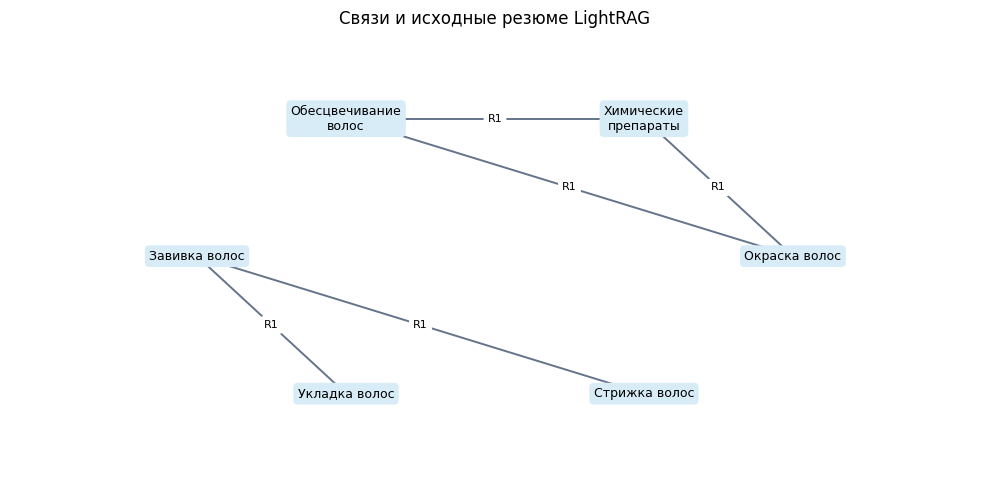

In [6]:
def evidence_ids(row):
    return {source["id"] for source in row["sources"]}

example = next(
    row for row in initial
    if row["method"] == "LongRAG" and row["trace"].get("groups")
    and evidence_ids(row).intersection(row["question"]["sources"])
)
group_id, match = next(iter(example["trace"]["groups"].items()))
groups, _ = index.groups(example["config"]["group_size"])
print(example["question"]["text"])
print(f"Лучший фрагмент из {match['source_id']} при L2 = {match['distance']:.2f}")
print(match["fragment"])
print(f"Группа {group_id}: {', '.join(index.public_ids[source.id] for source in groups[group_id].sources)}")
print(example["answer"])

graph_row = next(
    row for row in initial
    if row["config"]["method"] == "light"
    and any(set(edge["sources"]).intersection(row["question"]["sources"])
            for edge in row["trace"].get("edges", []))
)
edges = [edge for edge in graph_row["trace"]["edges"]
         if set(edge["sources"]).intersection(graph_row["question"]["sources"])][:5]
print(graph_row["question"]["text"])
links = pd.DataFrame([
    {"От": edge["from"], "К": edge["to"], "Связь": edge["description"],
     "Резюме": ", ".join(edge["sources"])}
    for edge in edges
])
show_table(links, "Связи графа, найденные по этому вопросу, и резюме, где они подтверждаются.",
           (20, 20, 46, 14))
graph = nx.Graph()
for edge in edges:
    graph.add_edge(edge["from"], edge["to"], sources=", ".join(edge["sources"]))
positions = nx.circular_layout(graph)
captions = {node: fill(node.replace("_", " "), 18) for node in graph}
fig, ax = plt.subplots(figsize=(10, 5))
nx.draw_networkx_edges(graph, positions, edge_color="#64748b", width=1.4, ax=ax)
nx.draw_networkx_edge_labels(graph, positions, edge_labels=nx.get_edge_attributes(graph, "sources"),
                             font_size=8, rotate=False, ax=ax)
nx.draw_networkx_labels(graph, positions, labels=captions, font_size=9, ax=ax,
                        bbox=dict(boxstyle="round,pad=0.35", facecolor="#d8ecf8", edgecolor="none"))
ax.margins(0.24)
ax.set_title("Связи и исходные резюме LightRAG")
ax.set_axis_off()
fig.tight_layout()
plt.show()

### Однофакторный подбор

Каждый вариант меняет один параметр и отвечает на все 12 вопросов.

In [7]:
with FileLock(runtime / "positional-400.lock", timeout=0):
    async with LightIndex(index, ollama) as light:
        experiment.study.light = light
        variants = await experiment.run("tuning", VARIANTS)
settings_results = tables(
    variants, "Результаты изменения одного параметра на всех 12 вопросах.",
    group="настройки",
)
score_matrix(settings_results, "Ручные баллы по каждому вопросу при изменении одного параметра.",
             settings=True)


Результаты изменения одного параметра на всех 12 вопросах.


настройки,Ответов,Средний балл,Среднее число токенов,"Среднее время, с"
"группа 1000, групп 3, вход 12000, T=0.1",12,0.92,2796.33,3.92
"группа 2000, групп 5, вход 12000, T=0.1",12,1.58,9626.0,5.75
"группа 2000, групп 3, вход 8000, T=0.1",12,1.0,5819.75,2.55
"mix, top_k=5, chunk_top_k=10, вход 12000, T=0.1",12,1.33,3395.0,3.53
"mix, top_k=20, chunk_top_k=3, вход 12000, T=0.1",12,1.0,1403.08,3.49
"mix, top_k=20, chunk_top_k=10, вход 8000, T=0.1",12,0.92,2542.75,2.6


Доля OK и показатели контекста по вариантам.


настройки,"Доля OK, %",Среднее число резюме,Среднее ближайшее L2²
"группа 1000, групп 3, вход 12000, T=0.1",50.0,8.58,10.28
"группа 2000, групп 5, вход 12000, T=0.1",91.67,29.33,9.75
"группа 2000, групп 3, вход 8000, T=0.1",66.67,16.42,10.03
"mix, top_k=5, chunk_top_k=10, вход 12000, T=0.1",75.0,10.0,9.7
"mix, top_k=20, chunk_top_k=3, вход 12000, T=0.1",66.67,3.0,10.35
"mix, top_k=20, chunk_top_k=10, вход 8000, T=0.1",58.33,6.33,9.81


Ручные баллы по каждому вопросу при изменении одного параметра.


Вариант RAG,F1,F2,F3,M1,M2,M3,S1,S2,S3,N1,N2,N3
"LongRAG · группа 1000, групп 3, вход 12000, T=0.1",2,0,0,0,0,0,1,0,2,2,2,2
"LongRAG · группа 2000, групп 5, вход 12000, T=0.1",2,2,2,0,1,1,1,2,2,2,2,2
"LongRAG · группа 2000, групп 3, вход 8000, T=0.1",2,0,0,0,1,1,1,0,1,2,2,2
"LightRAG mix · mix, top_k=5, chunk_top_k=10, вход 12000, T=0.1",2,2,0,0,1,2,1,0,2,2,2,2
"LightRAG mix · mix, top_k=20, chunk_top_k=3, вход 12000, T=0.1",2,0,0,0,1,1,1,0,1,2,2,2
"LightRAG mix · mix, top_k=20, chunk_top_k=10, вход 8000, T=0.1",2,0,0,0,0,1,1,0,1,2,2,2


### Температура

Для каждой выбранной поисковой настройки проверяются три температуры на всех 12 вопросах. Первый запуск и три повтора каждого вопроса используют один и тот же контекст. Время измеряется для генерации.


In [8]:
search_configs = experiment.select(initial, variants)
temperatures = []
if search_configs:
    with FileLock(runtime / "positional-400.lock", timeout=0):
        async with LightIndex(index, ollama) as light:
            experiment.study.light = light
            temperatures = await experiment.temperature(search_configs)
    temperature_results = tables(
        temperatures, "Генерация на 12 вопросах при разных температурах и фиксированном контексте.",
        group="настройки", show_repetition=True,
    )
    repeats = temperature_results.groupby("настройки", sort=False)
    summary = repeats.agg(Вопросов=("вопрос", "nunique"), Запусков=("ответ", "size"))
    summary["Запусков на вопрос"] = repeats["вопрос"].value_counts().groupby(level=0).min()
    same_as_first = temperature_results.groupby(["настройки", "вопрос"])["ответ"].nunique().eq(1)
    summary["Вопросов с одинаковыми ответами"] = same_as_first.groupby(level=0).sum()
    show_table(summary.reset_index(), "Покрытие вопросов и совпадение формулировок в повторах.",
               (47, 12, 11, 14, 16))
    score_matrix(temperature_results, "Средний балл четырёх запусков по каждому вопросу и температуре.",
                 settings=True, repeated=True)
else:
    print("Внесите ручные оценки однофакторных вариантов, чтобы выбрать поисковые настройки.")


Генерация на 12 вопросах при разных температурах и фиксированном контексте.


настройки,Ответов,Средний балл,Среднее число токенов,"Среднее время, с"
"группа 2000, групп 5, вход 12000, T=0.1",48,1.56,9626.0,2.36
"группа 2000, групп 5, вход 12000, T=0.4",48,1.5,9626.0,1.59
"группа 2000, групп 5, вход 12000, T=0.7",48,1.52,9626.0,1.59
"mix, top_k=5, chunk_top_k=10, вход 12000, T=0.1",48,1.33,3391.17,1.42
"mix, top_k=5, chunk_top_k=10, вход 12000, T=0.4",48,1.31,3391.17,1.27
"mix, top_k=5, chunk_top_k=10, вход 12000, T=0.7",48,1.33,3391.17,1.3


Доля OK и показатели контекста по вариантам.


настройки,"Доля OK, %",Среднее число резюме,Среднее ближайшее L2²
"группа 2000, групп 5, вход 12000, T=0.1",91.67,29.33,9.75
"группа 2000, групп 5, вход 12000, T=0.4",89.58,29.33,9.75
"группа 2000, групп 5, вход 12000, T=0.7",91.67,29.33,9.75
"mix, top_k=5, chunk_top_k=10, вход 12000, T=0.1",75.0,10.0,9.7
"mix, top_k=5, chunk_top_k=10, вход 12000, T=0.4",75.0,10.0,9.7
"mix, top_k=5, chunk_top_k=10, вход 12000, T=0.7",75.0,10.0,9.7


Покрытие вопросов и совпадение формулировок в повторах.


настройки,Вопросов,Запусков,Запусков на вопрос,Вопросов с одинаковыми ответами
"группа 2000, групп 5, вход 12000, T=0.1",12,48,4,7
"группа 2000, групп 5, вход 12000, T=0.4",12,48,4,4
"группа 2000, групп 5, вход 12000, T=0.7",12,48,4,4
"mix, top_k=5, chunk_top_k=10, вход 12000, T=0.1",12,48,4,7
"mix, top_k=5, chunk_top_k=10, вход 12000, T=0.4",12,48,4,4
"mix, top_k=5, chunk_top_k=10, вход 12000, T=0.7",12,48,4,3


Средний балл четырёх запусков по каждому вопросу и температуре.


Вариант RAG,F1,F2,F3,M1,M2,M3,S1,S2,S3,N1,N2,N3
"LongRAG · группа 2000, групп 5, вход 12000, T=0.1",2.0,2.0,2.0,0.0,1.0,1.0,1.0,1.75,2.0,2.0,2.0,2.0
"LongRAG · группа 2000, групп 5, вход 12000, T=0.4",2.0,2.0,2.0,0.0,1.0,0.75,1.0,1.25,2.0,2.0,2.0,2.0
"LongRAG · группа 2000, групп 5, вход 12000, T=0.7",2.0,2.0,2.0,0.0,1.0,1.0,1.0,1.25,2.0,2.0,2.0,2.0
"LightRAG mix · mix, top_k=5, chunk_top_k=10, вход 12000, T=0.1",2.0,2.0,0.0,0.0,1.0,2.0,1.0,0.0,2.0,2.0,2.0,2.0
"LightRAG mix · mix, top_k=5, chunk_top_k=10, вход 12000, T=0.4",2.0,2.0,0.0,0.0,1.0,1.75,1.0,0.0,2.0,2.0,2.0,2.0
"LightRAG mix · mix, top_k=5, chunk_top_k=10, вход 12000, T=0.7",2.0,2.0,0.0,0.0,1.0,2.0,1.0,0.0,2.0,2.0,2.0,2.0


## Сравнение и обновление базы

4. Сравните результаты и проверьте обновление

В таблице сохраняйте: **подход и режим → вопрос → настройки → источники → ответ → оценка → фактические токены входа → время ответа**. Отдельно укажите время построения индекса.

Оценка ответа: **0** — неверный или с выдуманными фактами; **1** — частично верный; **2** — полный и подтверждённый. Для вопроса без ответа корректное сообщение о недостатке данных — 2 балла. Проверяйте, что ссылки действительно подтверждают утверждения.

Отмечайте полноту найденных свидетельств, например **2 из 2**. Разберите **три показательных результата**: источник пропущен, факт искажён, улучшения нет или ответ стал точнее. Объясните причину; не придумывайте ошибки, если их не наблюдали.

Постройте **два графика**: средняя оценка и среднее время ответа итоговых конфигураций на тех же 12 вопросах. Укажите состояние кэша. Выводы относятся к вашему корпусу, а не ко всем RAG-системам.

Проверка после обновления базы

В **копии корпуса** для LightRAG добавьте или измените документ; укажите, что сделали со старой версией. Проверьте также два одноимённых, но разных объекта: при необходимости добавьте учебный пример с разными ID.

Выполните те же **три контрольных запроса** до и после обновления: новый факт должен появиться, прежний верный — сохраниться, чужие сведения — не приписаться объекту. Заранее запишите ожидаемые изменения; проверьте источники.

Пример: новое место работы кандидата учтено, прежний проект сохранён, навык однофамильца ему не приписан. Для своей темы выберите аналогичные факты. Это тесты RAG, а не опрос студентов.

### Ручная оценка

Два балла получает полный подтверждённый ответ или обоснованное сообщение о недостатке сведений. Частичный ответ получает один балл. Ошибка или необоснованный отказ получают ноль. При проверке учитываются содержание переданного контекста и полный текст указанного резюме. Полный ответ с подтверждённым альтернативным источником получает два балла.

Ответы получены от Qwen через Ollama. При возобновлении используются сохранённые результаты запросов. Ручные оценки применяются к совпадающим вопросу, ответу и найденным фрагментам. При получении нового ответа внесите его оценку функцией review_answer и повторите формирование таблиц.

Полнота показывает, сколько уникальных подтверждающих резюме попало в контекст из числа резюме в эталоне. Подходящие альтернативы засчитываются. Одно резюме может подтвердить две части ответа и принести полный балл, оставаясь одним источником. Прочерк выводится, когда в эталоне нет источников.

### Проверка обновления на вымышленных резюме

В копию графа LightRAG добавлены два вымышленных тёзки с ID U017 и U208. Эти ID используются только в проверке обновления. Обозначения U017-v1 и U017-v2 соответствуют двум версиям резюме U017. Меняется один факт о текущем проекте. Прежний факт должен остаться доступным, а сведения о Power BI из U208 должны остаться привязаны к тёзке. Вопросы U1–U3 проверяют эти три условия. Основное сравнение охватывает 12 других вопросов о корпусе R1–R400.


In [9]:
seed = experiment.study.light.directory
control_index = ResumeIndex([*corpus, UPDATE_OLD, UPDATE_OTHER], runtime)
variant = "update-positional-400"
control = Experiment(Study(control_index, ollama, system_prompt=SYSTEM_PROMPT),
                     CORPUS_SIZE, section=variant)
with FileLock(runtime / "positional-400.lock", timeout=0):
    async with LightIndex(control_index, ollama, variant=variant, seed_directory=seed) as light:
        control.study.light = light
        before = control.cached_rows("before", LIGHT, UPDATE_BEFORE)
        if len(before) != len(UPDATE_BEFORE):
            await light.build()
            before = await control.run("before", (LIGHT,), UPDATE_BEFORE)
        await light.replace(UPDATE_OLD.id, UPDATE_NEW)
        after = await control.run("after", (LIGHT,), UPDATE_AFTER)
previous = {row["question"]["id"]: row for row in before}
print("Три контрольных вопроса к вымышленным резюме в копии индекса.")
for row in after:
    question = row["question"]
    earlier = previous[question["id"]]
    comparison = pd.DataFrame([
        ("Ответ до", earlier["answer"]),
        ("Источники до", ", ".join(sorted(evidence_ids(earlier)))),
        ("Ожидаемый ответ после", question["expected"]),
        ("Ответ после", row["answer"]),
        ("Источники после", ", ".join(sorted(evidence_ids(row)))),
    ], columns=["Этап", "Результат"])
    show_table(comparison, f"{question['id']}. {question['text']}", (27, 73))

Три контрольных вопроса к вымышленным резюме в копии индекса.
U1. Над какой системой работает Алекс Маяков (ID U017) с января 2026 года?


Этап,Результат
Ответ до,В резюме нет достаточных сведений для ответа. [ID U017]
Источники до,U017-v1
Ожидаемый ответ после,С января 2026 года тестирует систему «Маяк».
Ответ после,Алекс Маяков (ID U017) работает с учебной системой «Маяк» [U017-v2].
Источники после,U017-v2


U2. В каком проекте Алекс Маяков (ID U017) разработал модуль проверки данных?


Этап,Результат
Ответ до,Алекс Маяков (ID U017) разработал модуль проверки данных проекта «Контроль качества» [U017-v1].
Источники до,U017-v1
Ожидаемый ответ после,Проект «Контроль качества».
Ответ после,Алекс Маяков (ID U017) разработал модуль проверки данных проекта «Контроль качества» [U017-v2].
Источники после,U017-v2


U3. Подтверждено ли, что Алекс Маяков (ID U017) использовал Power BI?


Этап,Результат
Ответ до,В резюме нет сведений о использовании Алекс Маяковым (ID U017) Power BI. [U017-v1]
Источники до,U017-v1
Ожидаемый ответ после,Нет сведений о Power BI у U017.
Ответ после,В резюме нет достаточных сведений для ответа. [ID U017]
Источники после,U017-v2


## Состав сдаваемой работы

Что сдать

**Один основной ноутбук .ipynb**, содержащий:

Работающий код трёх подходов на данных своего проекта; инструкции запуска, названия моделей, версии библиотек и краткий разбор двух исходных ноутбуков.

12 вопросов с ожидаемыми фактами и источниками; таблицу экспериментов, два графика, пример группы LongRAG и фрагмент графа LightRAG.

Три разобранных результата и проверку обновления: вопрос → ответ до → ожидаемый ответ после → фактический ответ после → источники.

**Вывод на 5–7 предложений:** что изменилось по сравнению с ML-HW10, какие настройки оказались лучше и хуже, какой вариант выбираете для своего проекта и почему.

**Продемонстрируйте работу через прежний чат:** добавьте выбор базовой RAG, LongRAG и LightRAG и покажите источники. Код чата и модулей вне ноутбука приложите отдельно. Не включайте API-ключи и персональные данные.

Если улучшения нет, зафиксируйте это и приведите примеры. **Результат работы — развитие своего проекта и обоснованное сравнение трёх подходов**, а не обязательная победа LongRAG или LightRAG.

Документация: HKUDS/LightRAG; QueryParam

### Итоговое сравнение

Поисковые настройки выбираются при общем входном бюджете по среднему баллу за 12 вопросов, полноте свидетельств и времени. Температура выбирается по среднему баллу, доле OK и времени на тех же вопросах. Итоговый прогон использует выбранные настройки для каждого из 12 вопросов. Базовая RAG сохраняет свои параметры поиска.


In [10]:
chosen = experiment.select_temperatures(search_configs, temperatures) if temperatures else None
final_rows = []
if chosen:
    with FileLock(runtime / "positional-400.lock", timeout=0):
        async with LightIndex(index, ollama) as light:
            experiment.study.light = light
            final_rows = await experiment.run("final", chosen)
    export_config(experiment.selected_config, (BASELINE, *chosen))
    baseline = [row for row in initial if row["config"]["method"] == "baseline"]
    results = tables(
        baseline + final_rows, "Итоговое сравнение базовой RAG и двух выбранных конфигураций по 12 вопросам."
    )
    score_matrix(results, "Ручные баллы по каждому вопросу в итоговом прогоне.")

    def rate(rows):
        if not rows or any(row["score"] is None for row in rows):
            return None
        return round(100 * sum(row["score"] > 0 for row in rows) / len(rows), 2)

    search_reviews = grade_rows(initial + variants)
    temperature_reviews = grade_rows(temperatures)
    test_reviews = grade_rows(final_rows)
    comparison = []
    changes = []
    for search, config in zip(search_configs, chosen, strict=True):
        selected_search = [row for row in search_reviews if row["config"] == asdict(search)]
        selected_temperature = [row for row in temperature_reviews if row["config"] == asdict(config)]
        selected_test = [row for row in test_reviews if row["config"] == asdict(config)]
        comparison.append({
            "Вариант RAG": f'{selected_test[0]["method"]} · {parameters(asdict(config))}',
            "Выбор поиска, %": rate(selected_search),
            "Выбор температуры, %": rate(selected_temperature),
            "Итоговый прогон, %": rate(selected_test),
        })
        if all(row["score"] is not None for row in selected_search + selected_test):
            before_ok = {row["question"]["id"] for row in selected_search if row["score"] > 0}
            after_ok = {row["question"]["id"] for row in selected_test if row["score"] > 0}
            if before_ok != after_ok:
                differences = [
                    f"{question.id} {'получил' if question.id in after_ok else 'потерял'} OK"
                    for question in questions if question.id in before_ok ^ after_ok
                ]
                changes.append(f'{selected_test[0]["method"]} — ' + ", ".join(differences) + ".")
    show_table(pd.DataFrame(comparison),
               "Доля OK у выбранных настроек на этапе подбора и в самостоятельном итоговом прогоне.",
               (46, 17, 19, 18))
    for change in changes:
        print(change)
else:
    print("Выбор итоговых настроек требует ручных оценок всех температур. "
          "Функция review_answer сохраняет ручную оценку.")

Итоговое сравнение базовой RAG и двух выбранных конфигураций по 12 вопросам.


подход,Ответов,Средний балл,Среднее число токенов,"Среднее время, с"
Базовая RAG,12,1.17,2004.5,5.02
LongRAG,12,1.5,9626.0,9.33
LightRAG mix,12,1.33,3391.17,4.27


Доля OK и показатели контекста по вариантам.


подход,"Доля OK, %",Среднее число резюме,Среднее ближайшее L2²
Базовая RAG,66.67,5.0,9.53
LongRAG,83.33,29.33,9.75
LightRAG mix,75.0,10.0,9.7


Ручные баллы по каждому вопросу в итоговом прогоне.


Вариант RAG,F1,F2,F3,M1,M2,M3,S1,S2,S3,N1,N2,N3
Базовая RAG,2,0,0,0,1,2,1,0,2,2,2,2
LongRAG,2,2,2,0,0,1,1,2,2,2,2,2
LightRAG mix,2,2,0,0,1,2,1,0,2,2,2,2


Доля OK у выбранных настроек на этапе подбора и в самостоятельном итоговом прогоне.


Вариант RAG,"Выбор поиска, %","Выбор температуры, %","Итоговый прогон, %"
"LongRAG · группа 2000, групп 5, вход 12000, T=0.1",91.67,91.67,83.33
"LightRAG mix · mix, top_k=5, chunk_top_k=10, вход 12000, T=0.7",75.0,75.0,75.0


LongRAG — M2 потерял OK.


### Оценки и время ответа

Стартовое сравнение, однофакторная проверка и итоговое сравнение используют одни и те же 12 вопросов. Их время включает поиск и генерацию. Графики температуры показывают среднее по четырём генерациям на каждом из 12 вопросов с фиксированным контекстом.


**Состояние кэша.** Индексы FAISS и граф LightRAG на этапах стартового сравнения, однофакторного подбора и итогового прогона переиспользовались: время на графиках включает поиск и генерацию и не включает построение индекса (оно указано отдельно, в таблице подготовки). Итоговая базовая RAG взята из стартового прогона с теми же параметрами поиска и заново не считалась. На графиках температуры контекст был заранее зафиксирован, кэш финального ответа отключался, а время измерено только для генерации; все 288 ответов получены отдельными запросами.


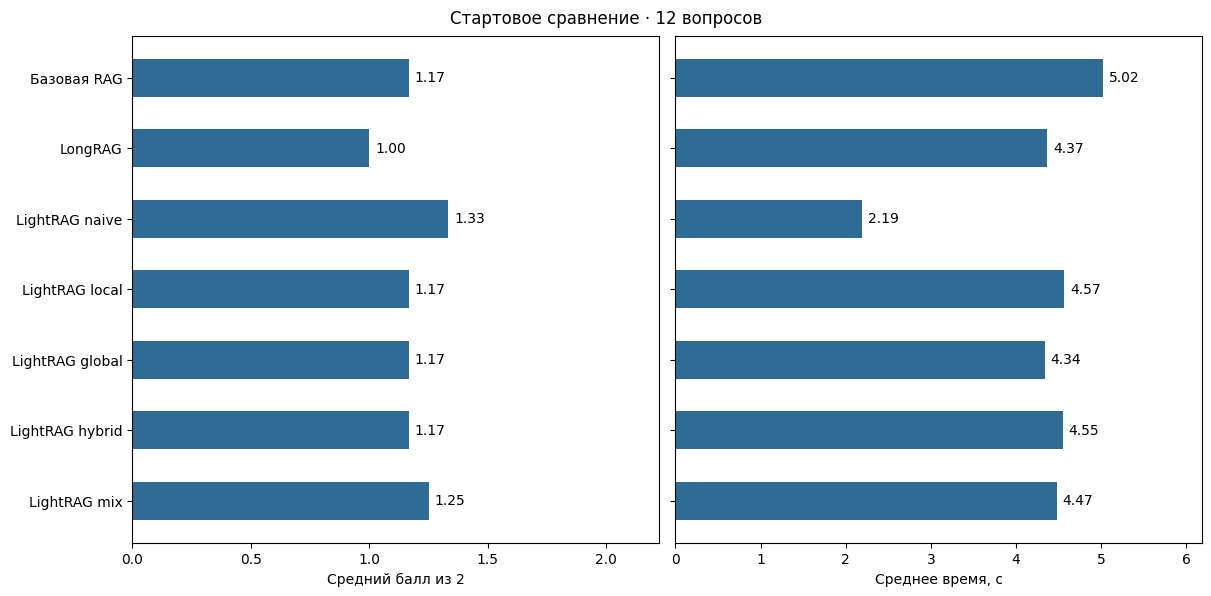

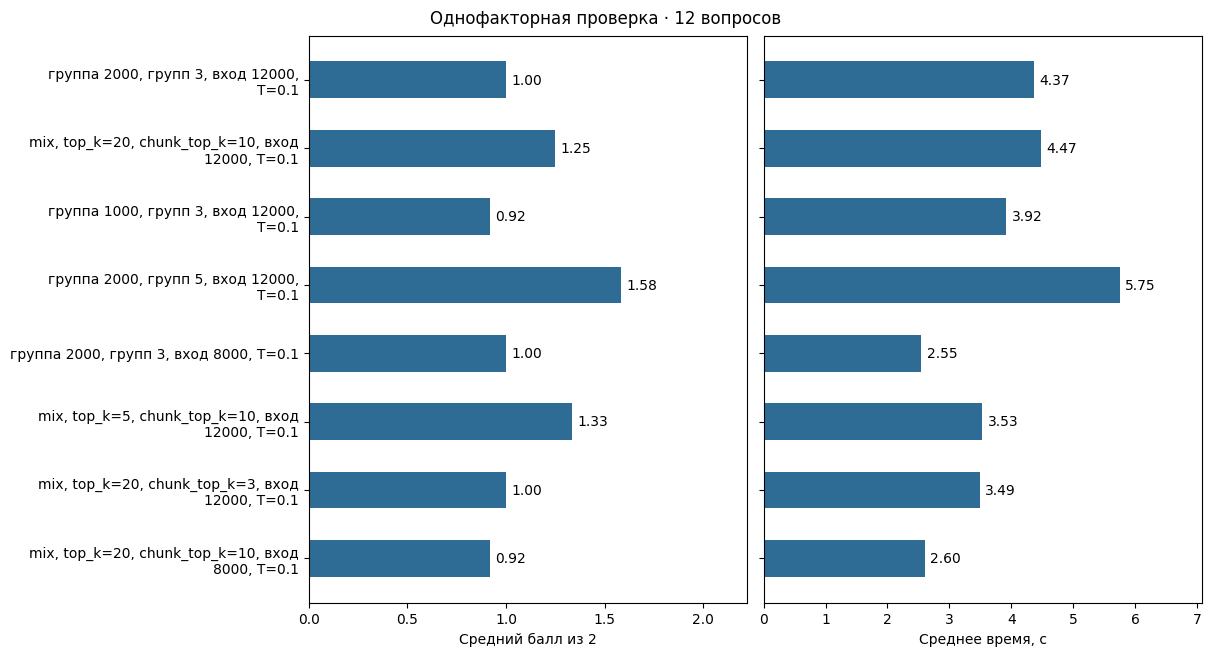

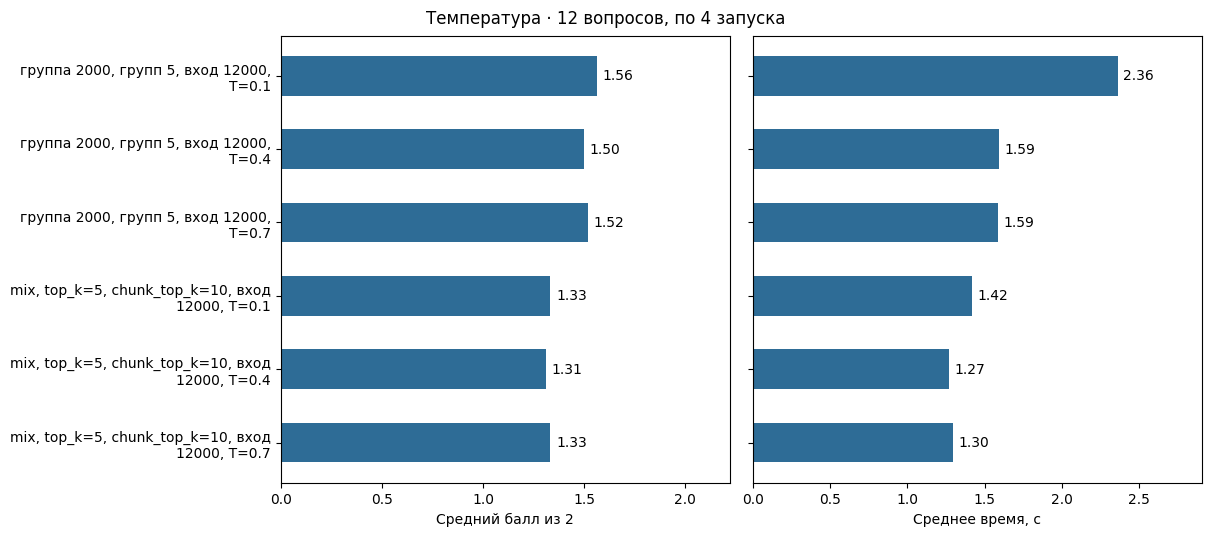

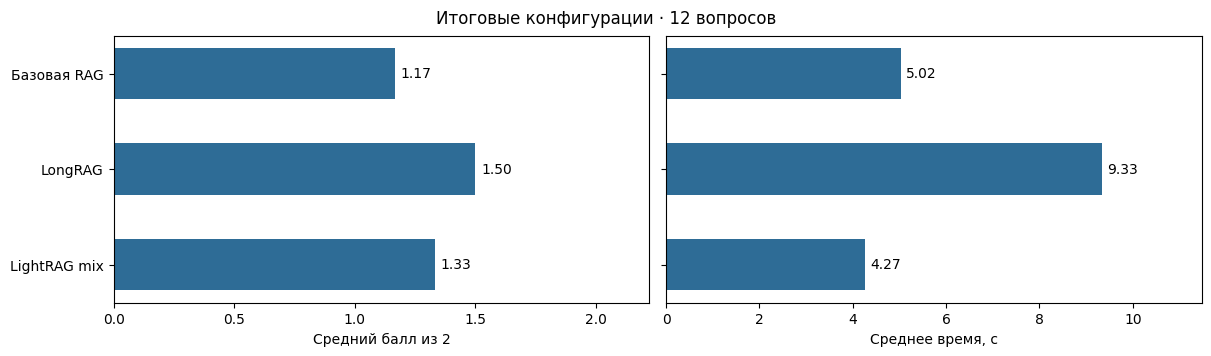

Базовая RAG · Кого из двух разных кандидатов подобрать для начисления зарплаты с удержанием НДФЛ и для работы с просроченной задолженностью?
Для начисления зарплаты с удержанием НДФЛ подойдёт R35 — упоминается исчисление и удержание НДФЛ, начисление премий, больничных, декретных, отпускных, командировочных, компенсаций [R35].  
Для работы с просроченной задолженностью подойдёт R303 — указано расчёт пени, урегулирование задолженности, контроль уплаты и мониторинг просроченных платежей [R303].  

В резюме нет достаточных сведений для точного определения, кто из кандидатов обладает опытом в работе с дебиторской задолженностью, что может быть важно для просроченных выплат. Однако по прямым упоминаниям ответы подтверждены. [R35] [R303]
R35 подтверждает расчёт зарплаты с НДФЛ. В R303 описаны начисление пени и урегулирование задолженности. Это подтверждённый альтернативный пример для второй задачи. 

LightRAG hybrid · Кого из двух разных кандидатов подобрать для начисления зарплаты с удержани

Вопрос,Ответ в корпусе,Основание
F1,Есть,Химическая завивка и окраска прямо названы в R1.
F2,Есть,В R3 полевые визиты и список целевых врачей относятся к одной должности.
F3,Есть,Работу с блюдами по технологическим картам подтверждает R308. Достаточно одного примера.
M1,Есть,"R308 готовил по картам, R214 составлял меню-раскладки и заявки на продукты."
M2,Есть,"R258 составлял маршруты доставки, R353 раскредитовывал накладные в ЭТРАН."
M3,Есть,"R35 начислял зарплату и удерживал НДФЛ, R110 работал с просроченной задолженностью."
S1,Есть,"В R5 указаны групповой и индивидуальный форматы, в R360 — виды тренингов."
S2,Есть,"Приход в 1С подтверждает R192, отгрузку — R14. В R16 описаны оба этапа."
S3,Есть,"R187 описывает строительный контроль, R266 — акты на скрытые работы."
N1,Нет,R367 описывает обязанности повара без дат и продолжительности работы.


Отказы на N1–N3 обоснованы отсутствием сведений. На F2 и S2 часть выдач не содержала нужных фактов, хотя они есть в корпусе. В одном из ответов LightRAG на F3 модель получила R308, но пропустила описанный в нём опыт.


In [11]:
def plot_comparison(frame, group, title):
    averages = frame.groupby(group, sort=False)[["балл", "секунды"]].mean()
    labels = [fill(str(label), width=38) for label in averages.index]
    positions = range(len(averages))
    fig, axes = plt.subplots(1, 2, sharey=True, figsize=(12, max(2.9, 1.65 + 0.60 * len(labels))),
                             layout="constrained")
    fig.suptitle(title)
    for ax, field, caption in zip(axes, ("балл", "секунды"), ("Средний балл из 2", "Среднее время, с")):
        bars = ax.barh(positions, averages[field], height=0.54, color="#2e6c96")
        ax.set_xlabel(caption)
        ax.set_xlim(0, 2.22 if field == "балл" else max(0.1, averages[field].max() * 1.23))
        if field == "балл":
            ax.set_xticks([0, 0.5, 1, 1.5, 2])
        ax.bar_label(bars, fmt="%.2f", padding=4)
    axes[0].set_yticks(positions, labels)
    axes[0].invert_yaxis()
    plt.show()


if initial_results["балл"].notna().all():
    plot_comparison(initial_results, "подход", "Стартовое сравнение · 12 вопросов")

defaults = initial_results.loc[
    initial_results["настройки"].isin(
        [parameters(asdict(INITIAL[1])), parameters(asdict(LIGHT))]
    )
]
one_factor = pd.concat([defaults, settings_results], ignore_index=True)
if one_factor["балл"].notna().all():
    plot_comparison(one_factor, "настройки", "Однофакторная проверка · 12 вопросов")
if temperatures and temperature_results["балл"].notna().all():
    plot_comparison(temperature_results, "настройки", "Температура · 12 вопросов, по 4 запуска")
if final_rows and results["балл"].notna().all():
    means = results.groupby("подход")[["балл", "секунды"]].mean()
    plot_comparison(results, "подход", "Итоговые конфигурации · 12 вопросов")

reviewed = [row for row in grade_rows(initial + variants + final_rows) if row["comment"]]
cases = (("initial", "Базовая RAG", "M3"), ("initial", "LightRAG hybrid", "M3"),
         ("tuning", "LongRAG", "S2"))
for phase, method, question in cases:
    match = next((row for row in reviewed if row["phase"] == phase and row["method"] == method
                  and row["question"]["id"] == question), None)
    if match:
        print(f"{match['method']} · {match['question']['text']}")
        print(match["answer"])
        print(match["comment"], "\n")

question_audit = {
    "F1": ("Есть", "Химическая завивка и окраска прямо названы в R1."),
    "F2": ("Есть", "В R3 полевые визиты и список целевых врачей относятся к одной должности."),
    "F3": ("Есть", "Работу с блюдами по технологическим картам подтверждает R308. Достаточно одного примера."),
    "M1": ("Есть", "R308 готовил по картам, R214 составлял меню-раскладки и заявки на продукты."),
    "M2": ("Есть", "R258 составлял маршруты доставки, R353 раскредитовывал накладные в ЭТРАН."),
    "M3": ("Есть", "R35 начислял зарплату и удерживал НДФЛ, R110 работал с просроченной задолженностью."),
    "S1": ("Есть", "В R5 указаны групповой и индивидуальный форматы, в R360 — виды тренингов."),
    "S2": ("Есть", "Приход в 1С подтверждает R192, отгрузку — R14. В R16 описаны оба этапа."),
    "S3": ("Есть", "R187 описывает строительный контроль, R266 — акты на скрытые работы."),
    "N1": ("Нет", "R367 описывает обязанности повара без дат и продолжительности работы."),
    "N2": ("Нет", "В корпусе не подтверждается рабочее администрирование Kubernetes."),
    "N3": ("Нет", "В корпусе не подтверждается оформление электронных авианакладных e-AWB."),
}
show_table(pd.DataFrame([
    (q.id, *question_audit[q.id]) for q in questions
], columns=["Вопрос", "Ответ в корпусе", "Основание"]),
    "Проверка всех 12 вопросов по полному корпусу резюме.", (10, 21, 69))
print("Отказы на N1–N3 обоснованы отсутствием сведений. "
      "На F2 и S2 часть выдач не содержала нужных фактов, хотя они есть в корпусе. "
      "В одном из ответов LightRAG на F3 модель получила R308, но пропустила описанный в нём опыт.")


**Источник пропущен.** На вопросах F2 и S2 часть выдач не передала в контекст подтверждающие резюме, хотя эти факты есть в корпусе: ответ получался неверным или неполным из-за поиска, а не из-за отсутствия сведений. В одном из ответов LightRAG на F3 в контекст попал R308, но модель не оперлась на описанный в нём опыт работы поваром и не дала полного подтверждённого ответа.


### Вывод

По сравнению с ML-HW10 мы сохранили прежний FAISS-поиск по полным резюме как базовый вариант, но расширили корпус с 18 до 400 документов и унифицировали генерацию: одна модель qwen3:4b-instruct, общий системный промпт и входной бюджет 12 000 токенов. В итоговом прогоне на тех же 12 вопросах лучший средний балл у LongRAG — 1,50 из 2 при группах до 2000 токенов, отборе пяти групп и температуре 0,1; базовая RAG набрала 1,17, выбранный LightRAG mix с top_k=5 и температурой 0,7 — 1,33. Из однофакторных настроек полезнее оказалось увеличить top_k_groups с 3 до 5: средний балл LongRAG вырос с 1,00 на старте до 1,58. Хуже сработали уменьшение группы до 1000 токенов (0,92) и урезание бюджета LightRAG до 8000 токенов (0,92). Пять стартовых режимов LightRAG были близки друг к другу, чуть выше оказались naive (1,33) и mix (1,25); температура почти не меняла средний балл, но при 0,4 и 0,7 формулировки чаще расходились между повторами. LongRAG при этом дольше и «дороже» по контексту: 9,33 с и около 9626 входных токенов против 5,02 с у базы и 4,27 с у LightRAG mix. Для своего проекта мы выбираем LongRAG с указанными настройками, потому что на контрольных вопросах он точнее, хотя за полноту приходится платить временем; если важнее скорость, разумная альтернатива — LightRAG mix. Все выводы относятся только к нашему корпусу обезличенных резюме и не переносятся автоматически на любые другие RAG-системы.


In [12]:
if final_rows and results["балл"].notna().all():
    best = means.sort_values(["балл", "секунды"], ascending=[False, True]).iloc[0]
    summary = (
        f"Лучший средний балл в итоговом прогоне у **{best.name}** — {best['балл']:.2f} из 2.",
        f"LongRAG использует группы до {chosen[0].group_size} токенов, отбирает {chosen[0].top_groups} "
        f"групп и отвечает при температуре {chosen[0].temperature}.",
        f"LightRAG использует режим `{chosen[1].mode}`, `top_k={chosen[1].light_top_k}` "
        f"и температуру {chosen[1].temperature}.",
        f"Температурная серия включала {len(temperatures)} генераций на 12 вопросах.",
        f"Среднее время ответа {best.name} в итоговом прогоне составило {best['секунды']:.2f} с.",
    )
    display(Markdown("\n".join(f"- {line}" for line in summary)))


- Лучший средний балл в итоговом прогоне у **LongRAG** — 1.50 из 2.
- LongRAG использует группы до 2000 токенов, отбирает 5 групп и отвечает при температуре 0.1.
- LightRAG использует режим `mix`, `top_k=5` и температуру 0.7.
- Температурная серия включала 288 генераций на 12 вопросах.
- Среднее время ответа LongRAG в итоговом прогоне составило 9.33 с.